# How Large Language Models Work
## A Plain-English Guide with Pure Python
### Designed for Non-Technical Audiences with lot of Pictures and code

---

Welcome! This notebook takes you **inside** an AI language model — step by step, using only simple Python.

You will discover how tools like ChatGPT, Gemini, and GitHub Copilot work under the hood.

Lets Begin!!!

## What You Will Learn

| # | Concept | What You Will Discover | Learn More |
|---|---|---|---|
| 1 | **Tokens** | How AI breaks text into pieces | [Try it interactively →](https://platform.openai.com/tokenizer) |
| 2 | **Parameters** | Where the model's knowledge lives | [Google ML Crash Course →](https://developers.google.com/machine-learning/crash-course) |
| 3 | **Embeddings** | How meaning becomes numbers | [Interactive 3D Visualiser →](https://projector.tensorflow.org/) |
| 4 | **Attention** | How AI decides what to focus on | [The Illustrated Transformer →](https://jalammar.github.io/illustrated-transformer/) |
| 5 | **Next-token prediction** | How text generation actually works | [Write with AI in real-time →](https://transformer.huggingface.co/) |
| 5B | **Thinking models** | How AI works things out before it answers | [IBM: what is a reasoning model? →](https://www.ibm.com/think/topics/reasoning-model) |
| 6 | **Training** | How AI learns from data | [Train a model in your browser →](https://teachablemachine.withgoogle.com/) |
| 7 | **RAG** | How AI connects to fresh, external knowledge | [AWS plain-English explainer →](https://aws.amazon.com/what-is/retrieval-augmented-generation/) |
| 8 | **Agents** | How AI takes actions instead of just answering | [What are AI agents? →](https://www.anthropic.com/research/building-effective-agents) |
| 9 | **MCP** | How tools are described and connected to AI | [MCP official docs →](https://modelcontextprotocol.io/) |
| 8B | **Guardrails** | How agents ask a person before risky actions | [OpenAI guide to building agents →](https://cdn.openai.com/business-guides-and-resources/a-practical-guide-to-building-agents.pdf) |
| 8C | **Decision models** | How AI picks from a fixed list, with a score | [Decision Models Lab →](https://shashikantdev3.github.io/decision-models-lab/) |

## Ground Rules

- **No heavy libraries** — only Python built-ins (math, random, re)
- **Every concept has a real-world analogy** — no prior tech knowledge needed
- **Run each cell** in order, top to bottom
- **Experiment** — change values and re-run to explore

> **Tip:** The best learning happens when you break things and observe what changes.


## 0. Helper Functions

These small utilities are used throughout the notebook.
You do not need to understand every line — just **run this cell first** before running anything else.

In [2]:

# ============================================================
# SECTION 0 — HELPER FUNCTIONS
# ============================================================
# These are small "tools" we will reuse throughout the notebook.
# You do NOT need to understand every line here.
# Just run this cell FIRST, then move on.
# Think of it like loading batteries before using a remote control.
# ============================================================

import math      # for square-root and exponent calculations
import random    # for making random choices (used in next-word prediction)
import re        # for splitting text using a pattern
from collections import Counter, defaultdict   # for counting things easily

# ---- Tool 1: Split a sentence into words (tokens) ----
def simple_tokenize(text):
    # Find all sequences of letters/numbers in the text, make them lowercase
    # Example: "Hello, World!" → ["hello", "world"]
    return re.findall(r"\b\w+\b", text.lower())

# ---- Tool 2: Print a dictionary in a readable way ----
def pretty_print_dict(d, limit=None):
    items = list(d.items())
    if limit is not None:
        items = items[:limit]
    for k, v in items:
        print(f"  {k!r}: {v}")

# ---- Tool 3: Convert raw scores into percentages that add up to 100% ----
# Used in the Attention section to turn "relevance scores" into probabilities
def softmax(scores):
    exp_scores = [math.exp(s) for s in scores]   # make all scores positive
    total = sum(exp_scores)
    return [s / total for s in exp_scores]        # divide each by the total

# ---- Tool 4: Draw a simple text bar so we can visualise numbers ----
# Example output:  "cat  |####----------|  0.600"
def bar_chart(label, value, max_value=1.0, width=30):
    filled = max(0, int((value / max_value) * width))
    bar = "#" * filled + "-" * (width - filled)
    print(f"  {label:<16} |{bar}| {value:.3f}")

print("✅ Helper functions loaded. You are ready to begin!")


✅ Helper functions loaded. You are ready to begin!


---
# 1. Tokens — How AI Reads Text

Before an AI model can process any text, it must break it into small pieces called **tokens**.

## The LEGO Analogy

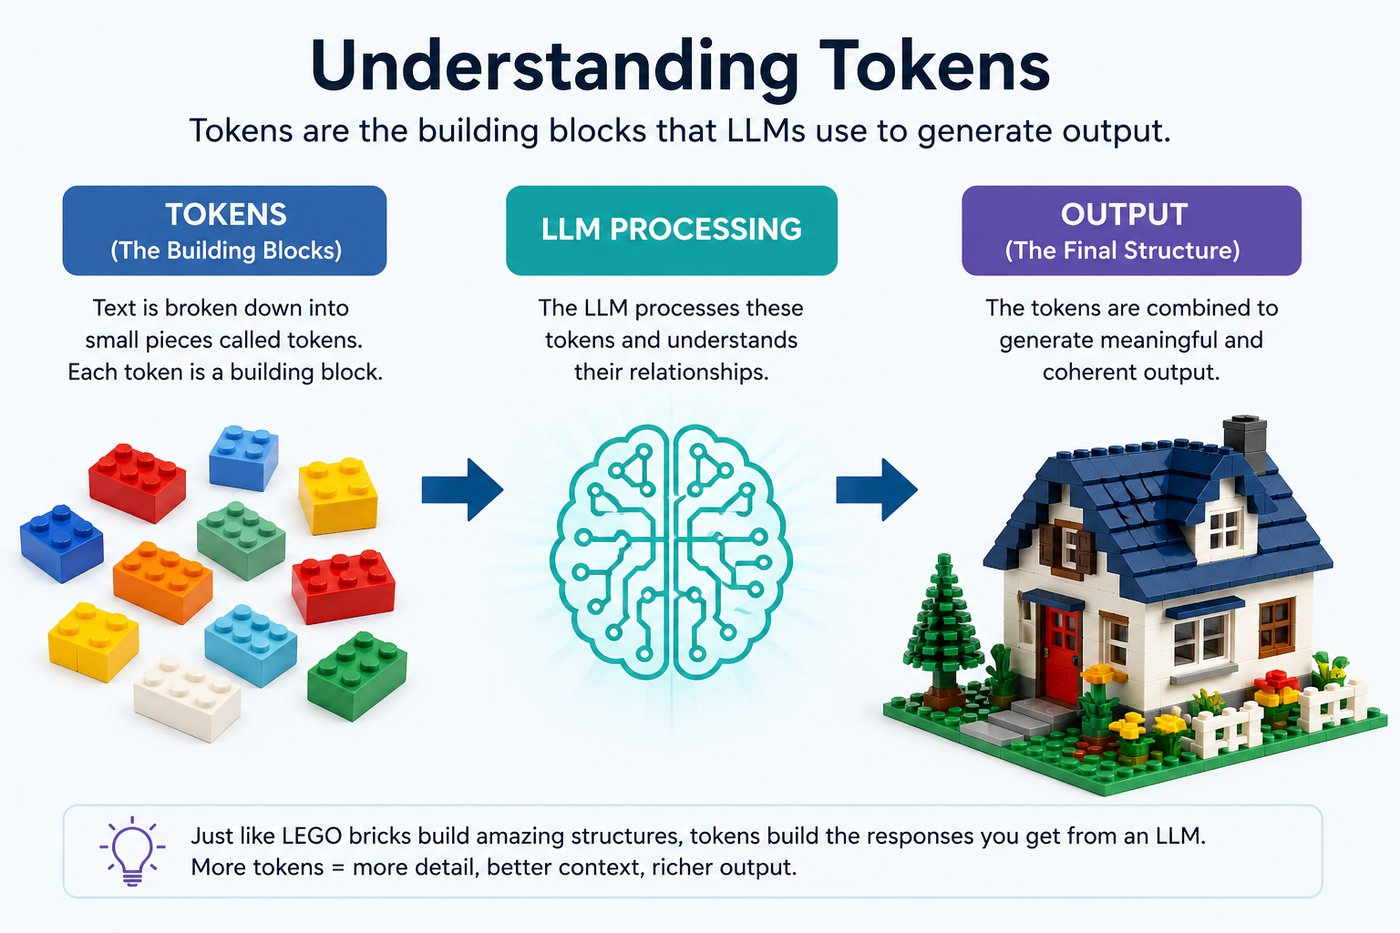

Imagine a sentence as a completed LEGO model.

- The **finished model** = the sentence
- Each **individual brick** = a token
- The AI always works with **bricks**, not the finished model

Before the AI can "think" about your sentence, it takes it apart brick by brick.

<div style="background:#1565c0;color:#ffffff;padding:18px 22px;border-radius:8px;margin:20px 0;font-size:1.1em;line-height:1.6;">
🔑 &nbsp;<strong style="font-size:1.1em;">Key idea:</strong><br><br>
AI doesn't process a sentence all at once — it first smashes it into small numbered pieces called <strong>tokens</strong>. Every single thing the model reads, writes, and thinks about is ultimately just a token.
</div>

---

## What counts as one token?

In real AI systems (like GPT-4), a token is roughly:
- A common short word: `the`, `is`, `cat`
- A chunk of a long word: `un` + `believ` + `able` = 3 tokens
- A punctuation mark: `.` `,` `!`
- A number or code symbol

For this notebook, we use whole lowercase words as tokens. Simpler than real LLMs, but teaches the same idea.

---

## Why not just use whole words — or individual letters?

This is a surprisingly important design decision, and AI researchers went back and forth on it for years.

| Approach | Example: `"unbelievable"` | Problem |
|---|---|---|
| **Characters** | `u`, `n`, `b`, `e`, `l`, `i`, `e`, `v`, `a`, `b`, `l`, `e` | Every sentence is thousands of steps long — very slow |
| **Whole words** | `unbelievable` | Rare or made-up words get no ID — model is confused |
| **Sub-words** ✅ | `un`, `believ`, `able` | Best of both worlds — handles rare words, keeps sequences short |

Real LLMs use **sub-word tokenisation** (specifically a technique called *Byte Pair Encoding*, or BPE). The idea: start with individual characters, then repeatedly merge the most common pairs until you have a useful vocabulary of ~100,000 pieces. Common words like `the` become a single token; rare words like `zucchini` get split into `z`, `uc`, `chi`, `ni`.

---

## Surprising tokenisation facts

- **Your name might be 3–4 tokens.** "Barnabas" → `Bar` + `na` + `bas` — the model processes it in pieces.
- **Spaces count.** In GPT tokenisation, `" dog"` (with a leading space) and `"dog"` are *different* tokens.
- **Code is expensive.** A Python function might use 3× more tokens than the equivalent plain-English description, because variable names are rare sub-words.
- **GPT-4's vocabulary has ~100,000 tokens.** Our notebook uses around 10–20. Same concept, massively different scale.

---

## Why does vocabulary size matter?

The vocabulary is fixed at **training time** and never changes during use. Every possible output the model can produce must be a token in that vocabulary. A vocabulary of 100,000 tokens means:
- The model can express ~100,000 distinct pieces of text
- The final layer of the model is a list of 100,000 probabilities — one for each possible next token

This is why adding a brand new word to an LLM isn't as simple as updating a dictionary — you'd have to retrain the entire model.

---

## The cost angle (in production AI)

When you call the OpenAI or Anthropic API, **you pay per token** — not per word, not per character, not per request. A typical English sentence has 15–25 tokens. A long document might be 10,000+ tokens. This is why AI engineers obsess over prompt length.

<div style="background:#e65100;color:#ffffff;padding:18px 22px;border-radius:8px;margin:20px 0;font-size:1.1em;line-height:1.6;">
💰 &nbsp;<strong style="font-size:1.1em;">Rule of thumb:</strong><br><br>
1 token ≈ 4 characters of English text, or about ¾ of a word.<br>
1,000 tokens ≈ 750 words ≈ a page and a half of text.<br><br>
When you call OpenAI or Anthropic, <strong>you pay per token</strong> — so token count is not just academic, it's a bill at the end of the month.
</div>


In [3]:
# A model does not see the sentence as a whole.
# It first breaks it into tokens (bricks), then processes each token.

text = "Generative AI is changing how people build software."

tokens = simple_tokenize(text)

print("Original sentence:")
print(" ", text)
print()
print("After breaking into tokens (bricks):")
print(" ", tokens)
print()
print(f"Token count: {len(tokens)}")
print()
print("Notice: punctuation is removed, everything is lowercase.")
print("In real LLMs, punctuation is also a token. Here we keep it simple.")

Original sentence:
  Generative AI is changing how people build software.

After breaking into tokens (bricks):
  ['generative', 'ai', 'is', 'changing', 'how', 'people', 'build', 'software']

Token count: 8

Notice: punctuation is removed, everything is lowercase.
In real LLMs, punctuation is also a token. Here we keep it simple.


### Why does tokenisation matter?

The way text is split into tokens affects **everything**:
- How long a "sentence" looks to the model
- Whether the model recognizes a word it has seen before
- How much memory and compute is needed

Try a few different sentences below and watch how the token count changes.

In [64]:
examples = [
    "AI is fun!!!!",
    "AI is very fun!",
    "AI, is it fun?",
    "Tokenization changes everything.",
    "The cat sat on the mat.",
]

for sentence in examples:
    toks = simple_tokenize(sentence)
    print(f"Sentence : {sentence}")
    print(f"Tokens   : {toks}")
    print(f"Count    : {len(toks)}")
    print("-" * 50)

Sentence : AI is fun!!!!
Tokens   : ['ai', 'is', 'fun']
Count    : 3
--------------------------------------------------
Sentence : AI is very fun!
Tokens   : ['ai', 'is', 'very', 'fun']
Count    : 4
--------------------------------------------------
Sentence : AI, is it fun?
Tokens   : ['ai', 'is', 'it', 'fun']
Count    : 4
--------------------------------------------------
Sentence : Tokenization changes everything.
Tokens   : ['tokenization', 'changes', 'everything']
Count    : 3
--------------------------------------------------
Sentence : The cat sat on the mat.
Tokens   : ['the', 'cat', 'sat', 'on', 'the', 'mat']
Count    : 6
--------------------------------------------------


## 1B. Token IDs — Turning Words Into Numbers

Here is a key insight that surprises many people:

<div style="background:#b71c1c;color:#ffffff;padding:20px 24px;border-radius:8px;margin:20px 0;font-size:1.15em;line-height:1.7;">
🚨 &nbsp;<strong style="font-size:1.15em;">The most important thing in this entire section:</strong><br><br>
<span style="font-size:1.3em;font-weight:bold;">An AI model NEVER actually sees words. It only ever sees NUMBERS.</span>
</div>

Every token gets a unique ID number from a lookup table called the **vocabulary**.

Think of it like a telephone directory:
- Each name (word) has exactly one phone number (ID)
- The model only dials numbers — it never types names

When you type `"hello"`, the model receives something like `15496`.

---

## Why numbers instead of words?

Computers are fundamentally number-crunching machines. They can add, multiply, and compare numbers in nanoseconds — but they have no built-in understanding of the letter `"c"` or the syllable `"un"`. By converting every token to a number first, we hand the model something it can actually do mathematics with. From that point on, it's all arithmetic: no strings, no characters, no text processing.

---

## The vocabulary — decided once, fixed forever

The token-ID lookup table is called the **vocabulary** (or *tokeniser*). A few important facts:

- It is built **once** during training on billions of documents
- It never changes after training — the same word always gets the same ID
- If a token doesn't appear in the vocabulary, the model literally cannot produce it (this is called out-of-vocabulary, or OOV)
- In GPT-4's tokeniser (`cl100k_base`), the vocabulary has **exactly 100,277 entries**

---

## The context window — how many IDs the model can hold at once

Once text becomes a sequence of numbers, the model processes them all together. But there is a hard limit on how long that sequence can be. This limit is called the **context window**.

| Model | Context window |
|---|---|
| GPT-3.5 | 4,096 tokens |
| GPT-4 Turbo | 128,000 tokens |
| Claude 3.7 Sonnet | 200,000 tokens |
| Gemini 1.5 Pro | 1,000,000 tokens |

Think of the context window as the model's **working memory** — it can reason about anything inside the window, but has no awareness of anything outside it. If your conversation grows beyond the window, the earliest messages quietly fall off the edge.

<div style="background:#1b5e20;color:#ffffff;padding:18px 22px;border-radius:8px;margin:20px 0;font-size:1.1em;line-height:1.6;">
💡 &nbsp;<strong style="font-size:1.1em;">Practical implication:</strong><br><br>
Summarising a 500-page book in one prompt is only possible with a large context window. Early models literally could not do it — not because they weren't smart enough, but because they couldn't hold enough token IDs in memory at once.
</div>

---

## From ID back to word — decoding

The same vocabulary table works in reverse. When the model predicts the next token, it outputs a number (say `9986`). The tokeniser converts that back to text (`"amazing"`). This back-and-forth — words → IDs → math → IDs → words — happens hundreds of times for every response you receive.


In [66]:
# ============================================================
# SECTION 1B — TOKEN IDs: Every Word Gets a Number
# ============================================================
# Our sentence:  "Let's build a tower with LEGO bricks ."
# Each word (token) gets a unique ID — just like a name badge.
# IDs start at 101 so they feel like a real lookup table.
# ============================================================

sentence = "Let's build a tower with LEGO bricks ."

# --- The Vocabulary: our hardcoded word → ID mapping ---
vocab = {
    "Let's"  : 101,
    "build"  : 102,
    "a"      : 103,
    "tower"  : 104,
    "with"   : 105,
    "LEGO"   : 106,
    "bricks" : 107,
    "."      : 108,
}

# Reverse lookup: ID → word (for decoding later)
id_to_word = {v: k for k, v in vocab.items()}

# --- Step 1: Show the vocabulary table ---
print("=" * 45)
print(f"  Vocabulary  (Token → ID)")
print("=" * 45)
print(f"  {'Token (Piece)':<14}  {'ID (Number)'}")
print("-" * 45)
for word, id_ in vocab.items():
    print(f"  {word:<14}  {id_}")

# --- Step 2: Encode the sentence ---
tokens   = sentence.split()          # split on spaces
token_ids = [vocab[t] for t in tokens]

print()
print("=" * 45)
print("  Sentence → Token IDs")
print("=" * 45)
print(f"  Sentence : {sentence}")
print(f"  Tokens   : {tokens}")
print(f"  IDs      : {token_ids}")

# --- Step 3: Decode back to words ---
decoded = [id_to_word[i] for i in token_ids]
print()
print("=" * 45)
print("  Decode: IDs → Words (reverse lookup)")
print("=" * 45)
print(f"  IDs     : {token_ids}")
print(f"  Words   : {decoded}")
print()
print("👉 The model only ever sees:  ", token_ids)
print("   It NEVER sees the words — only the numbers.")


  Vocabulary  (Token → ID)
  Token (Piece)   ID (Number)
---------------------------------------------
  Let's           101
  build           102
  a               103
  tower           104
  with            105
  LEGO            106
  bricks          107
  .               108

  Sentence → Token IDs
  Sentence : Let's build a tower with LEGO bricks .
  Tokens   : ["Let's", 'build', 'a', 'tower', 'with', 'LEGO', 'bricks', '.']
  IDs      : [101, 102, 103, 104, 105, 106, 107, 108]

  Decode: IDs → Words (reverse lookup)
  IDs     : [101, 102, 103, 104, 105, 106, 107, 108]
  Words   : ["Let's", 'build', 'a', 'tower', 'with', 'LEGO', 'bricks', '.']

👉 The model only ever sees:   [101, 102, 103, 104, 105, 106, 107, 108]
   It NEVER sees the words — only the numbers.


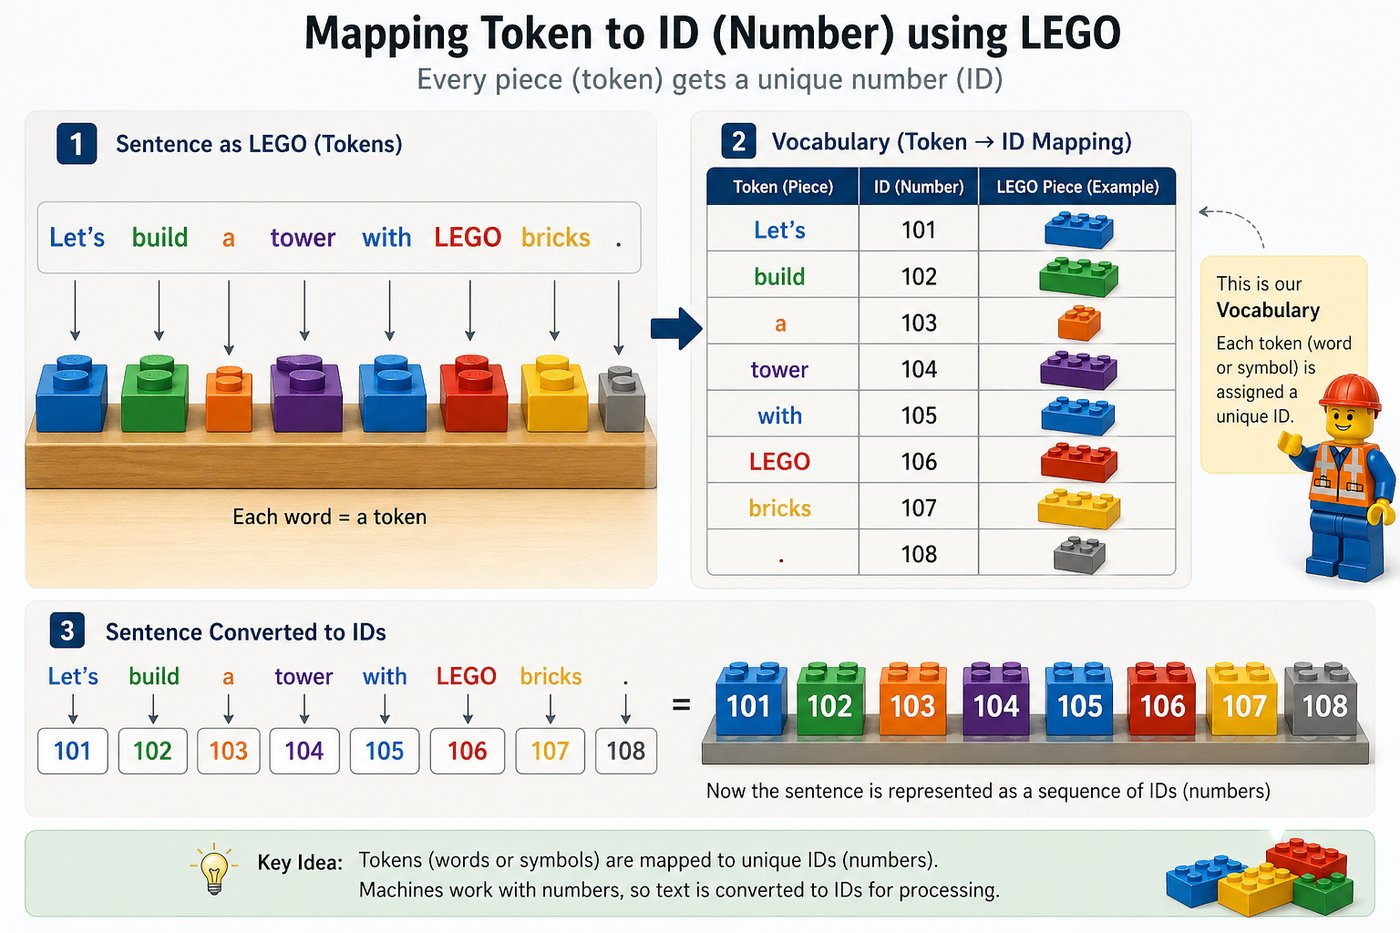

---
# 2. Parameters — Where the Model's Knowledge Lives

A **parameter** is a number inside the model that was adjusted during training.

## The Radio Analogy

Imagine an old radio with lots of tuning knobs:
- Each **knob** is a parameter
- When you tune the radio, you adjust the knobs until you get a clear signal
- **Training** is the process of turning millions of knobs until the model's output becomes accurate
- Once training is done, the knobs are locked — stored as numbers in a file

GPT-4 is estimated to have over **1 trillion** such knobs.

---

## The simplest possible model

The formula `score = weight × input + bias` has exactly 2 parameters:
- `weight` — how much the input matters
- `bias` — a baseline offset

This is the atom of every neural network.

In [67]:
def tiny_model(input, weight, bias):
    """The simplest possible model: one weight and one bias."""
    return weight * input + bias

# These are the model's parameters
weight = 2.5
bias   = 1.0

x = 3  # input

prediction = tiny_model(x, weight, bias)

print("Input          :", x)
print("Weight (param) :", weight)
print("Bias   (param) :", bias)
print("Prediction     :", prediction)
print()
print(f"Calculation: {weight} x {x} + {bias} = {prediction}")

Input          : 3
Weight (param) : 2.5
Bias   (param) : 1.0
Prediction     : 8.5

Calculation: 2.5 x 3 + 1.0 = 8.5


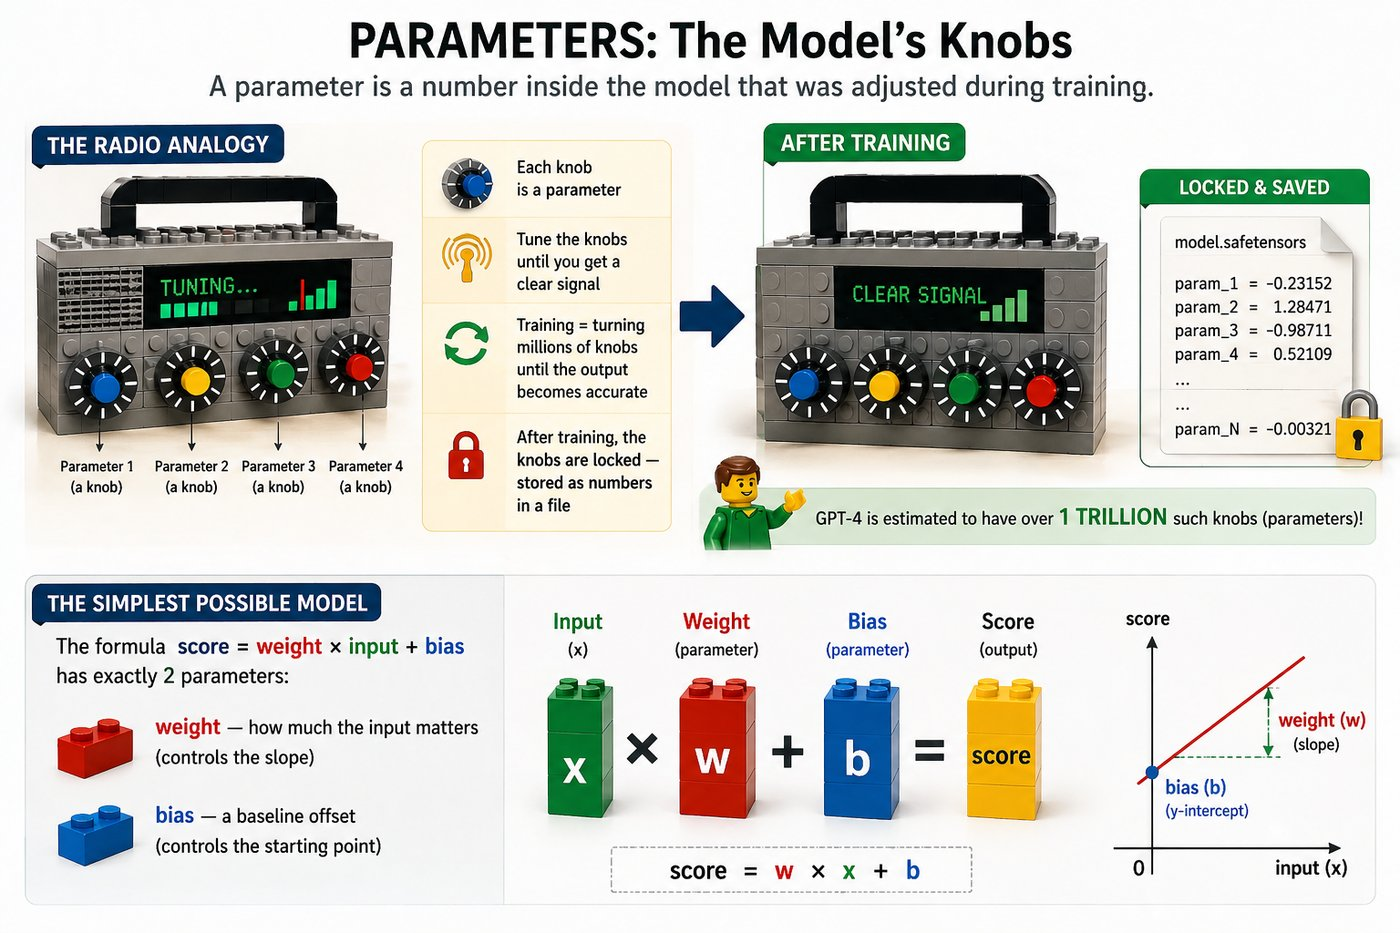

### Parameters control everything

Watch what happens when we use different parameter values with the same input.
This is the essence of **learning**: finding the parameter values that produce the right output.

In [47]:
input = 3

parameter_sets = [
    (1.0,  0.0),
    (2.0,  0.0),
    (2.0,  1.0),
    (5.0, -2.0),
    (0.1,  0.5),
]

print(f"Input x = {input} in all cases:")
print()
for weight, bias in parameter_sets:
    y = tiny_model(x, weight, bias)
    print(f"  weight={weight:>5}, bias={bias:>5}  ->  output = {y}")

Input x = 3 in all cases:

  weight=  1.0, bias=  0.0  ->  output = 3.0
  weight=  2.0, bias=  0.0  ->  output = 6.0
  weight=  2.0, bias=  1.0  ->  output = 7.0
  weight=  5.0, bias= -2.0  ->  output = 13.0
  weight=  0.1, bias=  0.5  ->  output = 0.8


### The scale of real models

Our toy model has **2** parameters (weight + bias).

Real language models are built from millions of these tiny operations, stacked and combined:

| Model | Approximate Parameters |
|---|---|
| GPT-2 (2019) | 1.5 billion |
| GPT-3 (2020) | 175 billion |
| GPT-4 (2023) | ~1 trillion (estimated) |
| Llama 3 (2024) | 8 – 70 billion |

Each parameter stores a tiny piece of learned knowledge — grammar, facts, coding patterns, reasoning habits.

> **Key message:** Parameters are the "memory" of the model. Training is the process of finding the right values for all of them.

---
# 3. Embeddings — How Meaning Becomes Numbers

An **embedding** is a list of numbers that represents a word or sentence.

The goal: words with **similar meanings** should have **similar numbers**.

## The City Map Analogy

Think of a city map where every word has its own address (coordinates):
- `king` and `queen` live on the same street
- `cat` and `dog` are neighbours
- `car` and `democracy` live in completely different neighbourhoods

When the model sees a new word, it looks up its address on the map.  
Finding *similar words* = finding *nearby addresses*.

Real embedding models map each token into a space with **hundreds or thousands of dimensions** (coordinates).
We will use a simple 2-step approach to build intuition.

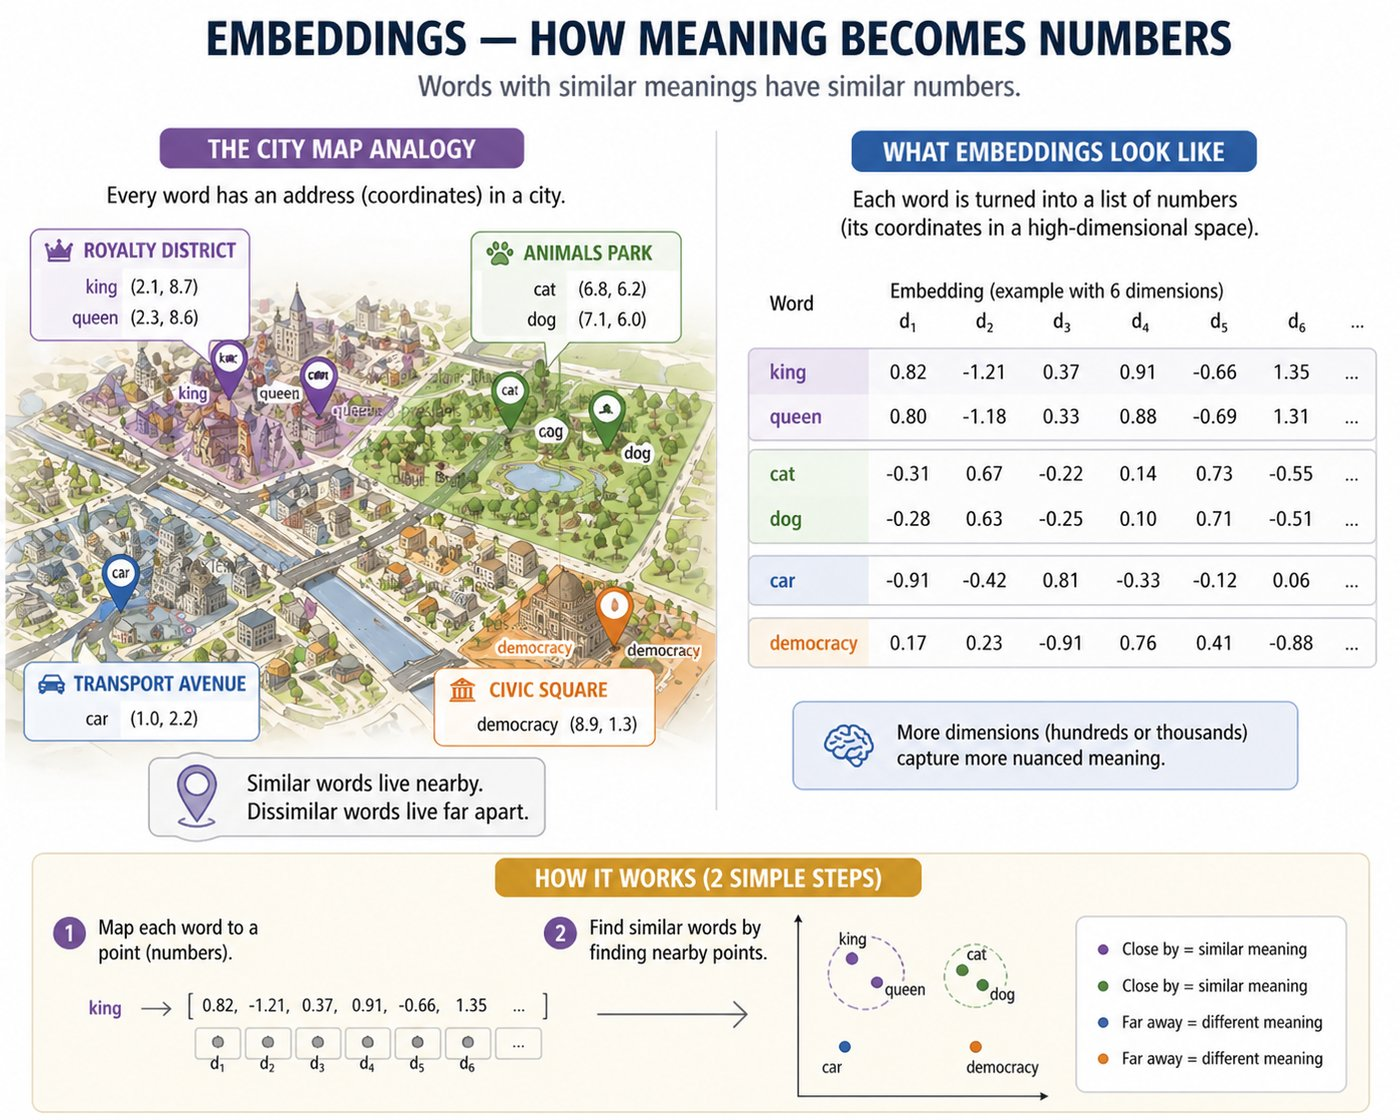

In [69]:

# ============================================================
# SECTION 3 — EMBEDDINGS: Turning Words Into Number Lists
# ============================================================
# A token ID (from Section 1B) is just a single number, like badge #4.
# An embedding goes much further: it describes the MEANING of a word
# as a whole LIST of numbers — like GPS coordinates on a city map.
#
# Words with similar meanings will end up at nearby coordinates.
# We build a simple version here using word counts.
# ============================================================

# --- Our three example sentences ---
sentences = [
    "cat drinks milk",
    "dog drinks water",
    "cat chases mouse",
]

# --- Step 1: Build a shared vocabulary (list of all unique words) ---
# Every sentence will be described using this same word list.
all_sentence_words = [simple_tokenize(s) for s in sentences]
vocabulary = sorted(set(word for sent in all_sentence_words for word in sent))

print("Shared vocabulary (all unique words across all sentences):")
print(" ", vocabulary)
print()

# --- Step 2: Represent each sentence as a simple count vector ---
# For each word in the vocabulary, count how many times it appears.
# This gives every sentence its "address" on the map.
def bag_of_words(sentence, vocab):
    # Count how often each word appears in this sentence
    word_counts = Counter(simple_tokenize(sentence))
    # Return counts in vocabulary order so all vectors are comparable
    return [word_counts[word] for word in vocab]

print("Vocabulary order:", vocabulary)
print()
print("Each sentence → its embedding (a count for each vocabulary word):")
print()
for s in sentences:
    embedding = bag_of_words(s, vocabulary)
    print(f"  Sentence : '{s}'")
    print(f"  Embedding: {embedding}")
    # Show which count belongs to which word
    explained = [f"{word}={count}" for word, count in zip(vocabulary, embedding)]
    print(f"  Meaning  : {explained}")
    print()


Shared vocabulary (all unique words across all sentences):
  ['cat', 'chases', 'dog', 'drinks', 'milk', 'mouse', 'water']

Vocabulary order: ['cat', 'chases', 'dog', 'drinks', 'milk', 'mouse', 'water']

Each sentence → its embedding (a count for each vocabulary word):

  Sentence : 'cat drinks milk'
  Embedding: [1, 0, 0, 1, 1, 0, 0]
  Meaning  : ['cat=1', 'chases=0', 'dog=0', 'drinks=1', 'milk=1', 'mouse=0', 'water=0']

  Sentence : 'dog drinks water'
  Embedding: [0, 0, 1, 1, 0, 0, 1]
  Meaning  : ['cat=0', 'chases=0', 'dog=1', 'drinks=1', 'milk=0', 'mouse=0', 'water=1']

  Sentence : 'cat chases mouse'
  Embedding: [1, 1, 0, 0, 0, 1, 0]
  Meaning  : ['cat=1', 'chases=1', 'dog=0', 'drinks=0', 'milk=0', 'mouse=1', 'water=0']



## 3B. Measuring Similarity with Cosine Similarity

Once we have embeddings (number lists), we can measure how **close** two sentences are.

We use **cosine similarity**:
- Result of **1.0** = identical direction (very similar meaning)
- Result of **0.0** = perpendicular (unrelated meaning)
- Result of **-1.0** = opposite direction (opposite meaning)

Imagine two arrows on the map — cosine similarity measures the angle between them.

In [70]:

# ============================================================
# SECTION 3B — COSINE SIMILARITY: How Close Are Two Sentences?
# ============================================================
# Now that each sentence is a list of numbers (an embedding),
# we can MEASURE how similar two sentences are.
#
# We use "cosine similarity":
#   • Score near 1.0 → sentences are very similar
#   • Score near 0.0 → sentences are unrelated
#
# Think of two arrows pointing in a direction on a map.
# Cosine similarity measures the ANGLE between those arrows.
# Small angle = pointing in the same direction = similar meaning.
# ============================================================

# --- Step 1: Two helper calculations ---

def dot_product(a, b):
    # Multiply matching numbers together, then add them all up.
    # Like comparing two sentences word-by-word and scoring the overlap.
    return sum(x * y for x, y in zip(a, b))

def vector_length(v):
    # The "length" of a list of numbers (Pythagoras applied to all dimensions).
    return math.sqrt(sum(x * x for x in v))

# --- Step 2: The similarity formula ---
def cosine_similarity(a, b):
    length_a = vector_length(a)
    length_b = vector_length(b)
    # Avoid dividing by zero if a sentence has no words in our vocabulary
    if length_a == 0 or length_b == 0:
        return 0.0
    # Divide the overlap score by both lengths to get a value between 0 and 1
    return dot_product(a, b) / (length_a * length_b)

# --- Step 3: Compare three sentences ---
s1 = "cat drinks milk"
s2 = "cat drinks water"    # shares TWO words with s1 ('cat', 'drinks')
s3 = "sun shines bright"   # shares ZERO words with s1

embeddings1 = bag_of_words(s1, vocabulary)
embeddings2 = bag_of_words(s2, vocabulary)
embeddings3 = bag_of_words(s3, vocabulary)

# --- Step 4: Show the embeddings so we can see what we are comparing ---
print("Vocabulary order:", vocabulary)
print()
print(f"  s1 '{s1}' → embedding: {embeddings1}")
print(f"  s2 '{s2}' → embedding: {embeddings2}")
print(f"  s3 '{s3}' → embedding: {embeddings3}")
print()

# --- Step 5: Walk through the calculation for s1 vs s2 in detail ---
print("=" * 60)
print("DETAILED CALCULATION: s1 vs s2")
print("=" * 60)

print()
print("Step A — Dot product (word-by-word overlap score):")
dp_s1_s2 = 0
for word, val1, val2 in zip(vocabulary, embeddings1, embeddings2):
    product = val1 * val2
    dp_s1_s2 += product
    print(f"  '{word}': {val1} × {val2} = {product}")
print(f"  ─────────────────────────────")
print(f"  Dot product total = {dp_s1_s2}")

print()
print("Step B — Vector lengths (how 'big' each embedding is):")
len_s1 = vector_length(embeddings1)
len_s2 = vector_length(embeddings2)
print(f"  Length of s1 = √({' + '.join(str(x*x) for x in embeddings1)}) = {len_s1:.4f}")
print(f"  Length of s2 = √({' + '.join(str(x*x) for x in embeddings2)}) = {len_s2:.4f}")

print()
print("Step C — Final division (normalise so the score is between 0 and 1):")
result = dp_s1_s2 / (len_s1 * len_s2)
print(f"  {dp_s1_s2} ÷ ({len_s1:.4f} × {len_s2:.4f})")
print(f"  {dp_s1_s2} ÷ {len_s1 * len_s2:.4f}")
print(f"  = {result:.3f}")

print()
print("=" * 60)
print("DETAILED CALCULATION: s1 vs s3")
print("=" * 60)
print()
print("Step A — Dot product:")
dp_s1_s3 = 0
for word, val1, val3 in zip(vocabulary, embeddings1, embeddings3):
    product = val1 * val3
    dp_s1_s3 += product
    print(f"  '{word}': {val1} × {val3} = {product}")
print(f"  ─────────────────────────────")
print(f"  Dot product total = {dp_s1_s3}  ← all zeros because NO shared words!")

print()
print("Step B — Because the dot product is 0, the final score is 0.0")
print("         (no shared words = no overlap = completely unrelated)")

print()
print("=" * 60)
print("SUMMARY")
print("=" * 60)

sim_s1_s2 = round(cosine_similarity(embeddings1, embeddings2), 3)
sim_s1_s3 = round(cosine_similarity(embeddings1, embeddings3), 3)

print()
print("Similarity scores (closer to 1.0 = more similar):")
bar_chart("s1 vs s2", sim_s1_s2)
bar_chart("s1 vs s3", sim_s1_s3)
print()
print("✅ s1 and s2 share 'cat' and 'drinks', so their dot product > 0 → score > 0.")
print("   s1 and s3 share nothing → dot product = 0 → score = 0.")
print()
print("In a real LLM, even sentences with DIFFERENT words but SAME meaning")
print("would score high — because the model learned meaning, not just spelling.")


Vocabulary order: ['cat', 'chases', 'dog', 'drinks', 'milk', 'mouse', 'water']

  s1 'cat drinks milk' → embedding: [1, 0, 0, 1, 1, 0, 0]
  s2 'cat drinks water' → embedding: [1, 0, 0, 1, 0, 0, 1]
  s3 'sun shines bright' → embedding: [0, 0, 0, 0, 0, 0, 0]

DETAILED CALCULATION: s1 vs s2

Step A — Dot product (word-by-word overlap score):
  'cat': 1 × 1 = 1
  'chases': 0 × 0 = 0
  'dog': 0 × 0 = 0
  'drinks': 1 × 1 = 1
  'milk': 1 × 0 = 0
  'mouse': 0 × 0 = 0
  'water': 0 × 1 = 0
  ─────────────────────────────
  Dot product total = 2

Step B — Vector lengths (how 'big' each embedding is):
  Length of s1 = √(1 + 0 + 0 + 1 + 1 + 0 + 0) = 1.7321
  Length of s2 = √(1 + 0 + 0 + 1 + 0 + 0 + 1) = 1.7321

Step C — Final division (normalise so the score is between 0 and 1):
  2 ÷ (1.7321 × 1.7321)
  2 ÷ 3.0000
  = 0.667

DETAILED CALCULATION: s1 vs s3

Step A — Dot product:
  'cat': 1 × 0 = 0
  'chases': 0 × 0 = 0
  'dog': 0 × 0 = 0
  'drinks': 1 × 0 = 0
  'milk': 1 × 0 = 0
  'mouse': 0 × 0 = 

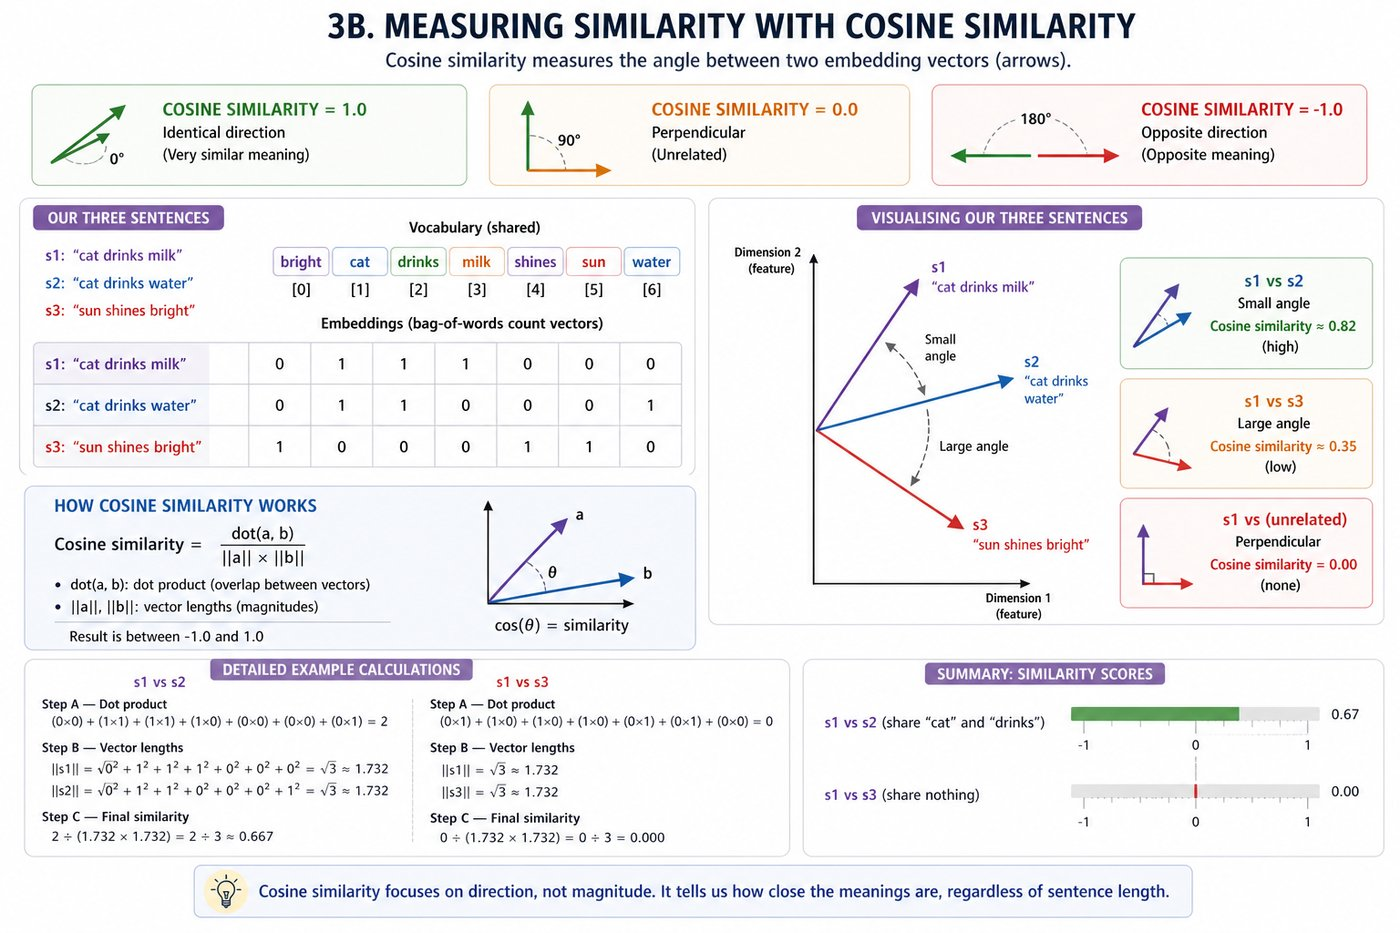

### The Big Idea

Real embedding models (like `text-embedding-ada-002` or `nomic-embed-text`) map every piece of text into a space with 768 or 1536 dimensions.

Words and sentences that **mean similar things** end up at **nearby coordinates** — automatically, because the model was trained on vast amounts of text.

This is why embeddings are used for:
- **Semantic search** — find documents by meaning, not just keywords
- **Recommendations** — find items similar to what you liked
- **RAG** — find the most relevant knowledge to attach to a prompt

---
# 4. Attention — How AI Decides What to Focus On

This is the breakthrough idea behind the "Transformer" architecture that powers all modern LLMs.

## The Doctor Analogy

Imagine a doctor reviewing a patient's medical file before a consultation.

- The file contains hundreds of data points — age, weight, shoe size, favourite colour, blood pressure, cholesterol, family history, sleep patterns...
- The doctor does **not** read every line with equal care
- When checking for heart disease, they immediately **spotlight** "cholesterol", "blood pressure", and "family history"
- They mostly **ignore** "shoe size" or "favourite colour" — those are irrelevant to the question at hand

Attention lets a model do exactly the same thing:
- For each word it is processing, it asks: *"which other words in this sentence are most relevant to me right now?"*
- It assigns high **attention weights** to relevant words and low weights to irrelevant ones
- It then builds its understanding by combining the weighted information

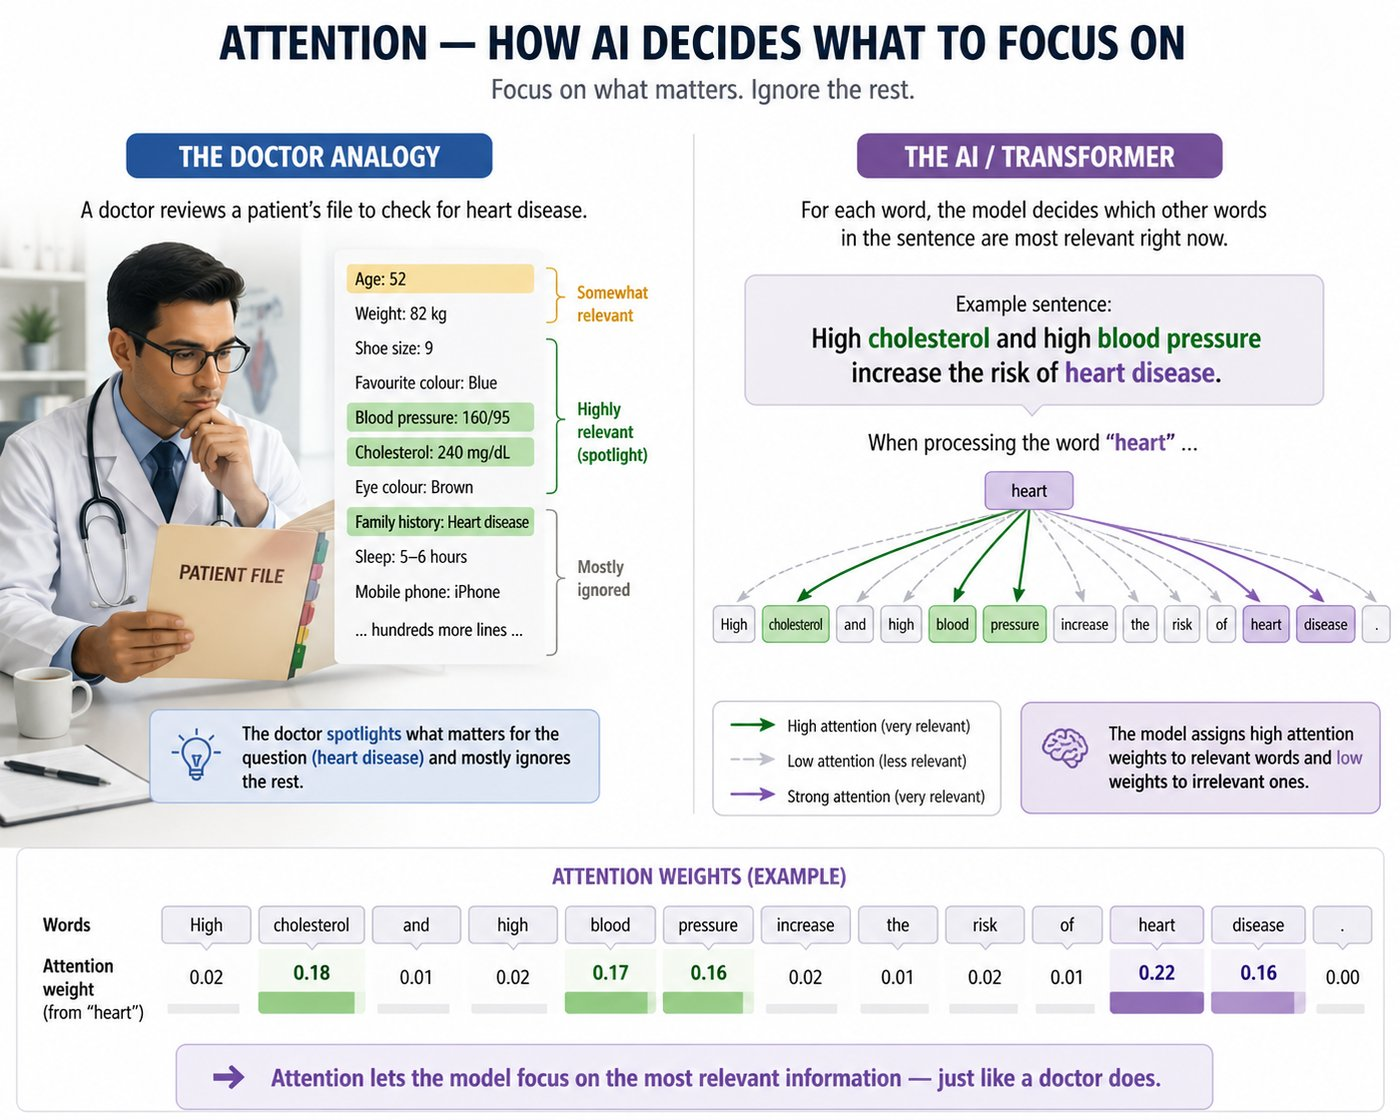

---

## Why attention solves a hard problem

Consider the word **"bank"** in two sentences:
- *"I deposited money at the **bank**."*  — financial meaning
- *"We had a picnic on the river **bank**."*  — geographical meaning

Without attention, the model would use the same meaning for "bank" in both cases.  
With attention, "bank" in sentence 1 attends strongly to "money" and "deposited".  
In sentence 2, "bank" attends strongly to "river" and "picnic".

In [72]:

# ============================================================
# SECTION 4 — ATTENTION: Which Words Matter Right Now?
# ============================================================
# In a real Transformer model, attention scores are calculated
# automatically by the model. Here we assign them manually so
# you can SEE the concept in action.
#
# For each word being processed, we ask:
#   "How relevant is every OTHER word in the sentence to ME?"
#
# Words that get a HIGH score = the model pays more attention to them.
# Words that get a LOW score  = the model mostly ignores them.
# ============================================================

def show_attention(target_word, sentence_words, raw_relevance_scores):
    """
    Visualise attention: show how much the model focuses on each word
    while processing 'target_word'.

    raw_relevance_scores: we manually set these to demonstrate the concept.
    Higher number = more relevant to 'target_word' in this context.
    """
    # Convert raw scores into proper percentages (they must add up to 100%)
    attention_weights = softmax(raw_relevance_scores)

    # Find the biggest weight so we can scale our bar chart nicely
    max_weight = max(attention_weights)

    print(f"👁  How much attention does '{target_word}' pay to each word?")
    print()
    for word, weight in zip(sentence_words, attention_weights):
        bar_chart(word, weight, max_value=max_weight)
    print()
    print("(Longer bar = more attention = more influence on the meaning of this word)")
    print()

# ============================================================
# EXAMPLE 1 — The word "bank" in a FINANCIAL sentence
# "I deposited money at the bank."
# ============================================================
print("=" * 55)
print("SENTENCE 1: 'I deposited money at the bank.'")
print("=" * 55)

financial_words  = ["I", "deposited", "money", "at", "the", "bank"]
# We manually say: "bank" should pay most attention to "money" and "deposited"
financial_scores = [0.2,  2.5,        3.0,     4.0,  0.1,   2.0]

show_attention("bank", financial_words, financial_scores)

# ============================================================
# EXAMPLE 2 — The SAME word "bank" in a GEOGRAPHICAL sentence
# "We had a picnic on the river bank."
# ============================================================
print("=" * 55)
print("SENTENCE 2: 'We had a picnic on the river bank.'")
print("=" * 55)

river_words  = ["We", "had", "a", "picnic", "on", "the", "river", "bank"]
# Now "bank" should pay most attention to "river" and "picnic"
river_scores = [0.1,  0.1,   0.1, 2.8,     0.2,  0.1,   3.5,    2.0]

show_attention("bank", river_words, river_scores)

print("💡 KEY INSIGHT:")
print("   The SAME word 'bank' attends to completely different words")
print("   depending on the sentence. This is how attention gives words")
print("   different meanings in different contexts — automatically.")


SENTENCE 1: 'I deposited money at the bank.'
👁  How much attention does 'bank' pay to each word?

  I                |------------------------------| 0.013
  deposited        |######------------------------| 0.126
  money            |###########-------------------| 0.208
  at               |##############################| 0.565
  the              |------------------------------| 0.011
  bank             |####--------------------------| 0.077

(Longer bar = more attention = more influence on the meaning of this word)

SENTENCE 2: 'We had a picnic on the river bank.'
👁  How much attention does 'bank' pay to each word?

  We               |#-----------------------------| 0.018
  had              |#-----------------------------| 0.018
  a                |#-----------------------------| 0.018
  picnic           |##############----------------| 0.263
  on               |#-----------------------------| 0.020
  the              |#-----------------------------| 0.018
  river            |#######

### What the demo shows

- In the **financial context**, the word "bank" pays most attention to "money" and "deposited"
- In the **river context**, the same word "bank" shifts its focus to "river" and "picnic"

The **meaning of a word changes based on context** — and attention is the mechanism that makes this possible.

In real transformers, this calculation happens **in parallel for every word, in every layer**. A model like GPT-4 may have 96 layers, each running attention over the entire input. That is why transformers are so capable — and so compute-intensive.

> **Key message:** Attention lets the model understand that the same word can mean different things in different sentences.

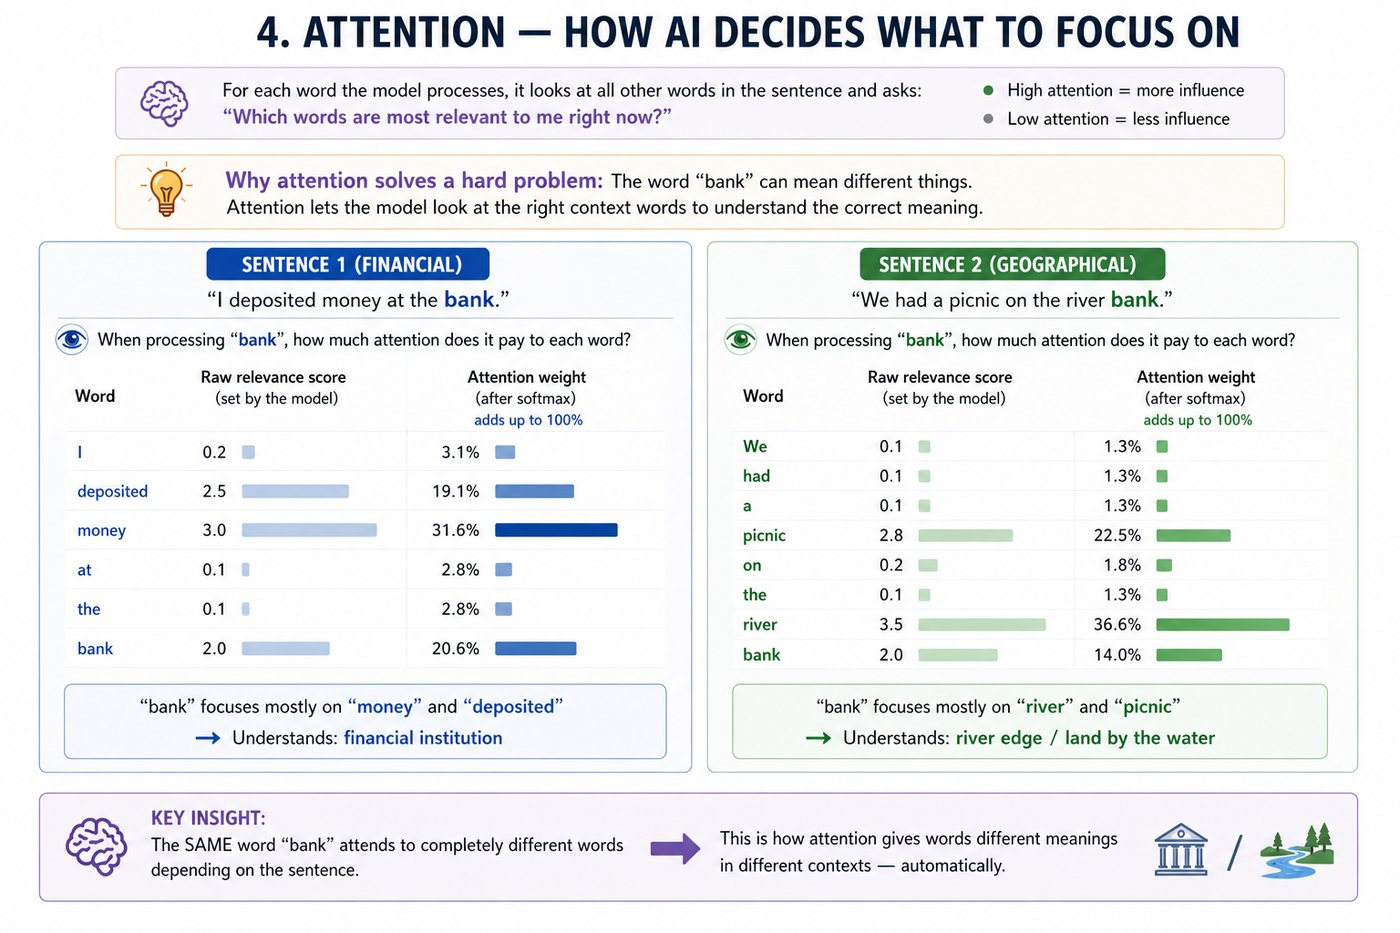

---
# 5. Next-Token Prediction — How AI Generates Text

After all the processing (tokens → embeddings → attention → parameters), a language model does one very simple thing:

> **It predicts the most likely next token.**

Then it appends that token and predicts the next one. And the next. And so on.

## The Autocomplete Analogy

You have seen this on your phone keyboard — it suggests the next word as you type.

A language model is a vastly more powerful autocomplete:
- Your phone keyboard learns from *your* typing patterns
- A language model learns from *billions of web pages, books, and code*

---

## 5A. Build a tiny prediction model from text

We will look at every consecutive word pair and count what comes next.

In [73]:
training_text = """
the cat sits on the mat
the cat eats fish
the dog sits on the rug
the dog eats food
the cat sits by the dog
the cat plays with the dog
"""

training_tokens = simple_tokenize(training_text)

# For every word, count what word follows it
next_word_model = defaultdict(Counter)

for current, next_w in zip(training_tokens, training_tokens[1:]):
    next_word_model[current][next_w] += 1

print("What words follow 'cat'? (word: count)")
pretty_print_dict(next_word_model['cat'])

print()
print("What words follow 'the'? (word: count)")
pretty_print_dict(next_word_model['the'])

print()
print("Each entry represents a learned pattern — just like parameters in a real LLM.")

What words follow 'cat'? (word: count)
  'sits': 2
  'eats': 1
  'plays': 1

What words follow 'the'? (word: count)
  'cat': 4
  'mat': 1
  'dog': 4
  'rug': 1

Each entry represents a learned pattern — just like parameters in a real LLM.


In [74]:
def predict_next_word(word, model):
    """Return the most likely next word."""
    options = model.get(word)
    if not options:
        return None
    return options.most_common(1)[0][0]

print("Most likely next word:")
print()
for word in ["the", "cat", "dog", "sits", "eats", "plays"]:
    nw = predict_next_word(word, next_word_model)
    print(f"  After '{word}' -> '{nw}'")

Most likely next word:

  After 'the' -> 'cat'
  After 'cat' -> 'sits'
  After 'dog' -> 'sits'
  After 'sits' -> 'on'
  After 'eats' -> 'fish'
  After 'plays' -> 'with'


In [75]:
def generate_text(start_word, model, steps=10):
    """Generate a sequence by repeatedly predicting the next word."""
    words = [start_word]
    current = start_word
    for _ in range(steps):
        next_w = predict_next_word(current, model)
        if next_w is None:
            break
        words.append(next_w)
        current = next_w
    return " ".join(words)

print("Generated text (always picks the most probable next word):")
print()
for start in ["the", "cat", "dog"]:
    print(f"  Start='{start}': {generate_text(start, next_word_model)}")

print()
print("Notice: because we always pick the top prediction, the output loops.")
print("This is called a 'greedy' strategy. Real models use smarter strategies — but that is beyond this notebook.")

Generated text (always picks the most probable next word):

  Start='the': the cat sits on the cat sits on the cat sits
  Start='cat': cat sits on the cat sits on the cat sits on
  Start='dog': dog sits on the cat sits on the cat sits on

Notice: because we always pick the top prediction, the output loops.
This is called a 'greedy' strategy. Real models use smarter strategies — but that is beyond this notebook.


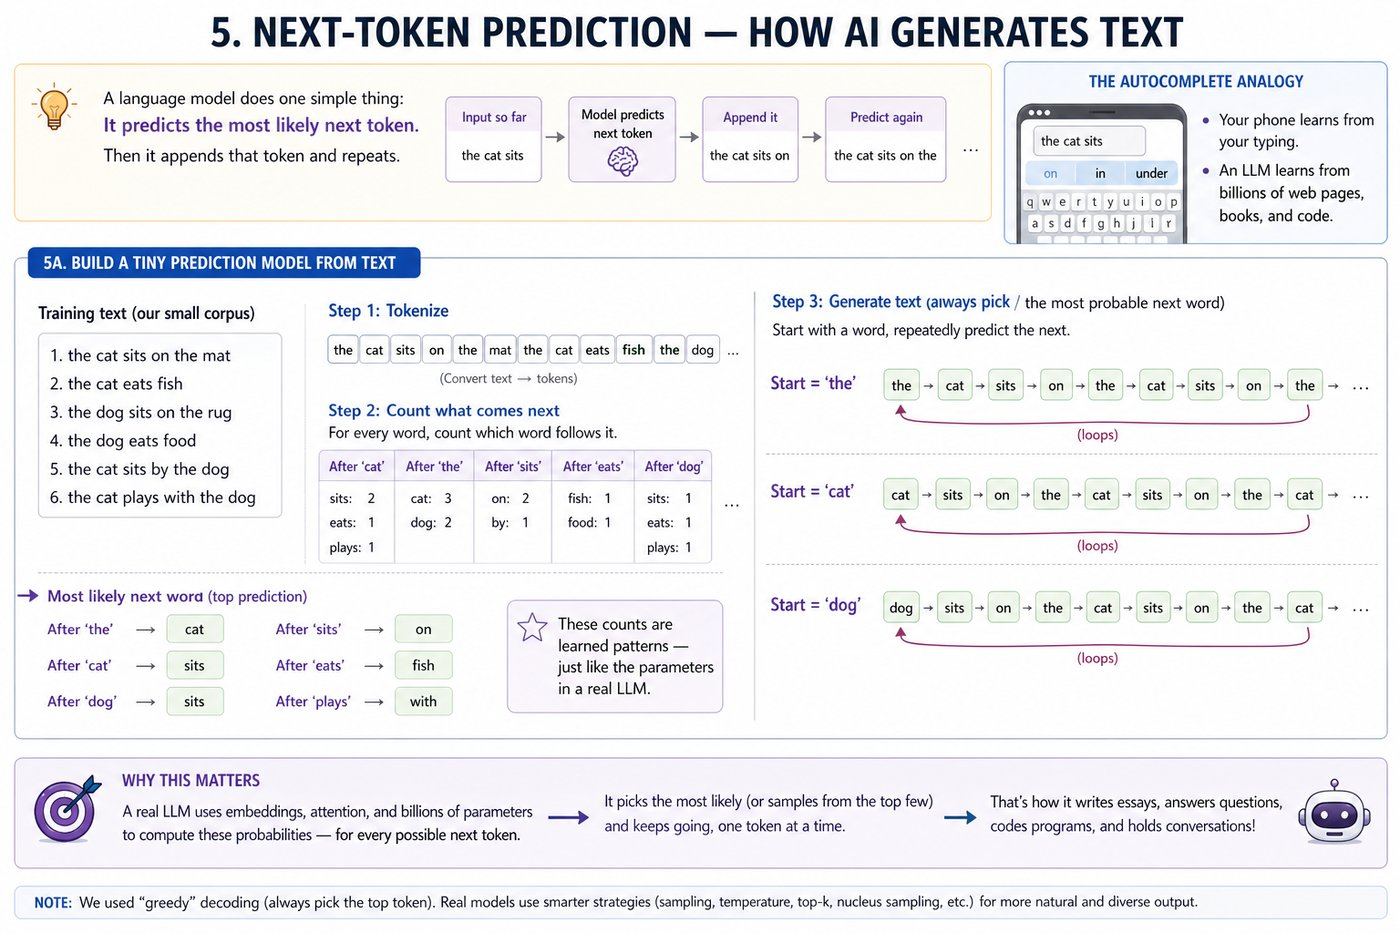

---
## 5B. Thinking Models — AI That Works It Out Before Answering

Section 5 showed that a model writes its answer one token at a time, starting straight away.

Newer AI tools add a step before the answer. On harder questions, the model first writes out its working, checks it, and only then gives you the final answer. You usually see only a short summary of that working, or nothing at all. These are called **thinking models**, also known as reasoning models. In some apps you will see a "Thinking..." message, or a choice between a fast mode and a thinking mode.

## The Scratch Paper Analogy

Think of a student in a maths exam:
- **Answering at once:** looks at the question and writes down the first number that comes to mind. Quick, but often wrong.
- **Thinking first:** works it out on scratch paper, checks it, then writes the final answer. Slower, but right far more often.

A thinking model does the second. Its scratch paper is extra tokens it writes for itself before the answer.

## The Trade-off

| | Answer at once | Think first |
|---|---|---|
| **Speed** | Fast | Slower |
| **Cost** | Fewer tokens | More tokens (the scratch paper counts too) |
| **Hard questions** | More mistakes | Fewer mistakes |
| **Good for** | Simple questions, quick replies | Maths, planning, code, tricky questions |

In [81]:
# ============================================================
# SECTION 5B — THINKING MODELS: Answer at Once vs Think First
# ============================================================
# We can't build a real thinking model here, but we can show
# the trade-off it makes.
#
# Our tiny "model" answers multiplication questions.
# Answering at once, it is right only about 6 times in 10.
#
# "Thinking first" = working the question out several times
# on scratch paper, then keeping the answer that came up most.
# More work before answering, but far fewer mistakes.
# ============================================================

ATTEMPTS = 9   # how many times the model works it out before answering

def answer_at_once(a, b):
    """Answer straight away: right about 6 times in 10."""
    correct = a * b
    if random.random() < 0.6:
        return correct
    return correct + random.choice([-10, -1, 1, 10])   # a near miss

def think_first(a, b, attempts=ATTEMPTS):
    """Work it out several times on scratch paper, keep the most common answer."""
    scratch_paper = [answer_at_once(a, b) for _ in range(attempts)]
    return Counter(scratch_paper).most_common(1)[0][0]

# ---- One question, step by step ----
random.seed(1)
a, b = 23, 47
scratch_paper = [answer_at_once(a, b) for _ in range(ATTEMPTS)]

print(f"❓ Question: {a} × {b} = ?   (correct answer: {a * b})")
print()
print(f"⚡ Answer at once : {answer_at_once(a, b)}")
print(f"📝 Scratch paper  : {scratch_paper}")
print(f"🧠 Think first    : {Counter(scratch_paper).most_common(1)[0][0]}  (the answer that came up most)")
print()

# ---- 200 questions, to see the pattern ----
random.seed(1)
questions = [(random.randint(10, 99), random.randint(10, 99)) for _ in range(200)]
right_at_once = sum(answer_at_once(a, b) == a * b for a, b in questions)
right_thinking = sum(think_first(a, b) == a * b for a, b in questions)

print("Share of 200 questions answered correctly:")
bar_chart("Answer at once", right_at_once / 200)
bar_chart("Think first", right_thinking / 200)
print()
print(f"Answer at once : {right_at_once}/200 right, 1 attempt per question")
print(f"Think first    : {right_thinking}/200 right, {ATTEMPTS} attempts per question ({ATTEMPTS}x the work)")

❓ Question: 23 × 47 = ?   (correct answer: 1081)

⚡ Answer at once : 1071
📝 Scratch paper  : [1081, 1071, 1081, 1081, 1081, 1080, 1081, 1081, 1091]
🧠 Think first    : 1081  (the answer that came up most)

Share of 200 questions answered correctly:
  Answer at once   |###################-----------| 0.650
  Think first      |############################--| 0.965

Answer at once : 130/200 right, 1 attempt per question
Think first    : 193/200 right, 9 attempts per question (9x the work)


### What you just saw

- **Answering at once** got about 6 in 10 questions right.
- **Thinking first** got almost all of them right, but did 9 times the work.

That is the real trade-off with thinking models. They are slower and use more tokens, so they cost more, but they make far fewer mistakes on hard questions. Remember the cost angle from Section 1: every token costs money, and the scratch paper is tokens too. That's why many AI apps let you pick a quick mode for everyday questions and a thinking mode for the hard ones.

> **Honest note:** real thinking models don't just answer several times and vote. They write out their reasoning step by step and can spot and fix their own mistakes along the way. Our demo only shows the idea behind it: more work before answering gives better answers.

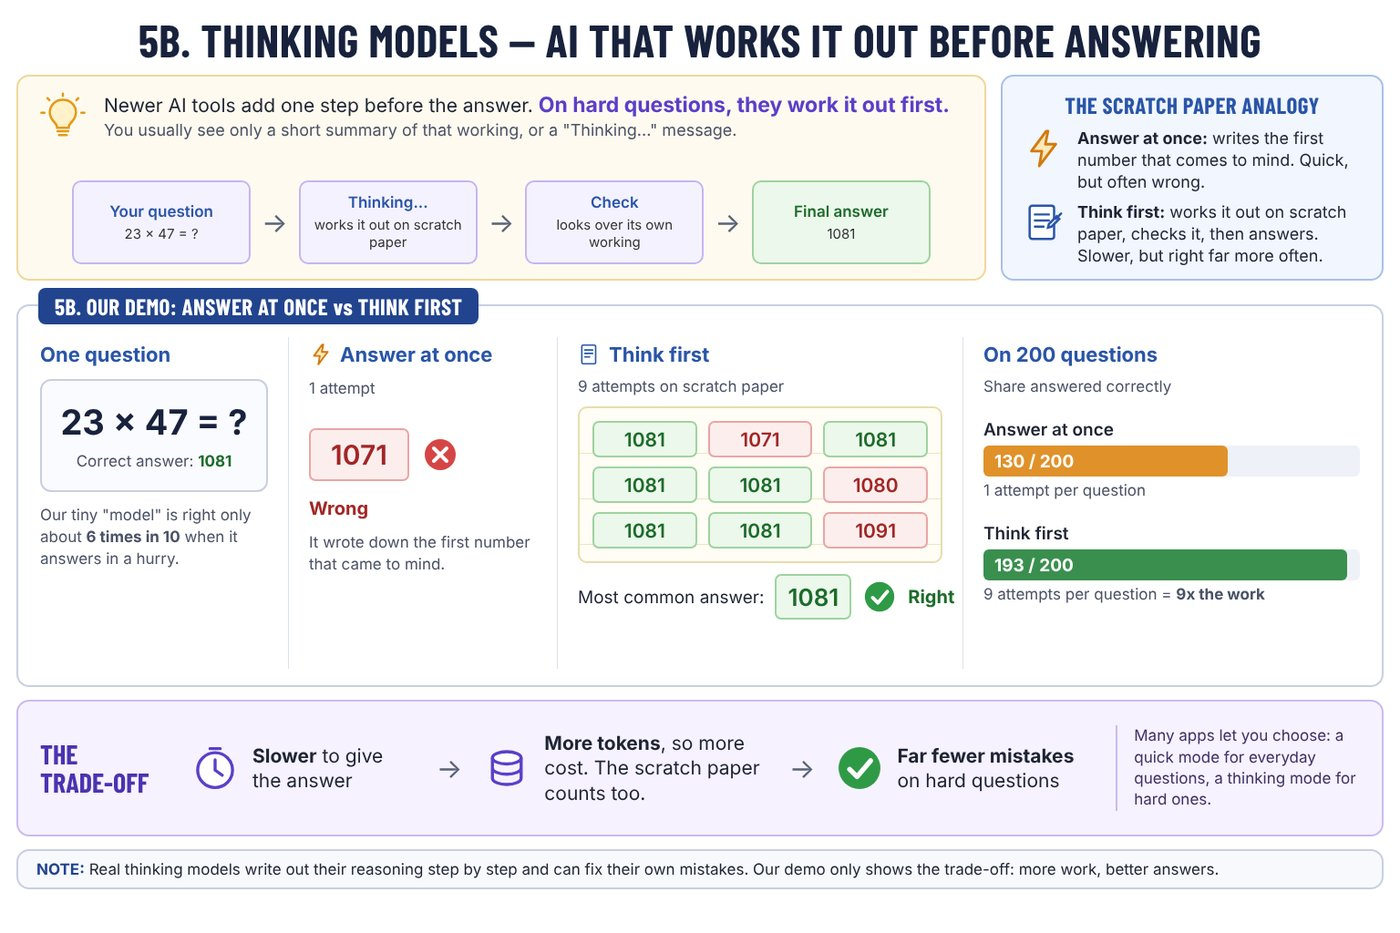

---
# 6. Training — How AI Learns From Data

So far we have *used* parameters. But where do they come from?

## The GPS Navigation Analogy

Imagine teaching someone to navigate a city:
1. They start with a **random route** — probably wrong
2. You measure how far off they are (the **loss**)
3. You give them a tiny hint about which direction to adjust
4. They take a small step in that direction
5. Repeat millions of times

This process is called **gradient descent**.  
After enough repetitions, the route converges to the correct one.

---

## What is "loss"?

Loss = how wrong the model's prediction is right now.  
Training = repeatedly reducing the loss by adjusting parameters.

A real LLM trains on trillions of tokens. Each token is a chance to adjust the parameters slightly.

In [33]:

# ============================================================
# SECTION 6 — TRAINING: How the Model Learns
# ============================================================
# We will teach a tiny model to discover the rule: y = 2x + 1
#
# For example:  input 1 → output 3
#               input 2 → output 5
#               input 3 → output 7  ... and so on.
#
# The model starts with RANDOM guesses for weight and bias.
# After each attempt it checks how wrong it was (the "loss").
# Then it nudges weight and bias slightly in the right direction.
# Repeat 200 times → the model finds the right answer on its own.
#
# This is EXACTLY what training a real LLM does —
# just with billions of parameters instead of 2.
# ============================================================

# --- The correct answers the model must learn to predict ---
# Each pair is (input x, correct output y)
# The hidden rule is  y = 2 * x + 1
training_examples = [
    (1, 3),    # 2×1 + 1 = 3
    (2, 5),    # 2×2 + 1 = 5
    (3, 7),    # 2×3 + 1 = 7
    (4, 9),    # 2×4 + 1 = 9
    (5, 11),   # 2×5 + 1 = 11
]

# --- Start with random guesses ---
random.seed(99)   # fixed seed so everyone gets the same starting point
weight = random.uniform(0, 5)    # a random starting guess for the slope
bias   = random.uniform(-3, 3)   # a random starting guess for the offset

learning_rate = 0.01   # how big a step to take each time (too big = overshoot)

print(f"🎲 Starting random guess:  weight = {weight:.3f},  bias = {bias:.3f}")
print(f"🎯 What we want to reach: weight = 2.000,  bias = 1.000")
print()
print(f"{'Step':<8}  {'Weight':<12}  {'Bias':<12}  {'Error (loss)'}")
print("-" * 50)

# --- The training loop ---
for step in range(201):

    # ---- Step A: Calculate how wrong we are right now ----
    # For each training example, see how far off our prediction is.
    # Then compute the gradient — the direction we need to nudge the parameters.
    gradient_weight = 0.0
    gradient_bias   = 0.0

    for x, correct_answer in training_examples:
        our_prediction = weight * x + bias          # what we predict
        mistake        = our_prediction - correct_answer   # how wrong we are

        # These formulas tell us which direction to move weight and bias
        # (derived from calculus, but you don't need to know that)
        gradient_weight += 2 * mistake * x
        gradient_bias   += 2 * mistake

    # Average the gradient over all training examples
    gradient_weight /= len(training_examples)
    gradient_bias   /= len(training_examples)

    # ---- Step B: Nudge the parameters a tiny bit ----
    # Subtract because we want to go DOWNHILL (reduce the error)
    weight -= learning_rate * gradient_weight
    bias   -= learning_rate * gradient_bias

    # ---- Print progress every 40 steps ----
    if step % 40 == 0:
        # Calculate total loss (average squared mistake across all examples)
        total_loss = sum(
            (weight * x + bias - y) ** 2
            for x, y in training_examples
        ) / len(training_examples)
        print(f"{step:<8}  {weight:<12.4f}  {bias:<12.4f}  {total_loss:.6f}")

print()
print(f"✅ Final learned values: weight = {weight:.4f},  bias = {bias:.4f}")
print(f"   True correct values: weight = 2.0000,  bias = 1.0000")
print()
print("The model started from random guesses and found the right answer")
print("just by repeatedly asking: 'Which direction reduces my mistakes?'")
print()
print("A real LLM does this same process — across TRILLIONS of examples.")


🎲 Starting random guess:  weight = 2.020,  bias = -1.800
🎯 What we want to reach: weight = 2.000,  bias = 1.000

Step      Weight        Bias          Error (loss)
--------------------------------------------------
0         2.1835        -1.7447       4.882234
40        2.6280        -1.2674       0.935801
80        2.5485        -0.9802       0.713703
120       2.4790        -0.7293       0.544317
160       2.4183        -0.5102       0.415132
200       2.3653        -0.3189       0.316607

✅ Final learned values: weight = 2.3653,  bias = -0.3189
   True correct values: weight = 2.0000,  bias = 1.0000

The model started from random guesses and found the right answer
just by repeatedly asking: 'Which direction reduces my mistakes?'

A real LLM does this same process — across TRILLIONS of examples.


### What you just witnessed

| Concept | In our demo | In a real LLM |
|---|---|---|
| Parameters | 2 (weight, bias) | Billions |
| Training data | 5 examples | Trillions of tokens |
| Training steps | 200 | Millions of batches |
| Loss function | Mean Squared Error | Cross-entropy over next token |
| Optimiser | Basic gradient descent | Adam, AdamW, etc. |

The principle is identical — only the scale is different.

---
# 7. RAG — Retrieval-Augmented Generation

A trained LLM knows only what it saw during training. It cannot know:
- What happened last week
- Your company's internal documents
- Your personal notes

**RAG** solves this by connecting the model to an external knowledge base at query time.

## The Open-Book Exam Analogy

- A model without RAG = a student doing a **closed-book exam** — relies only on memory
- A model with RAG = a student doing an **open-book exam** — can look things up before answering

## The Three Steps of RAG

```
User question
     |
     v
[1. RETRIEVE]  -- search the knowledge base for relevant documents
     |
     v
[2. AUGMENT]   -- add the retrieved documents to the prompt
     |
     v
[3. GENERATE]  -- the model answers using the retrieved context
```

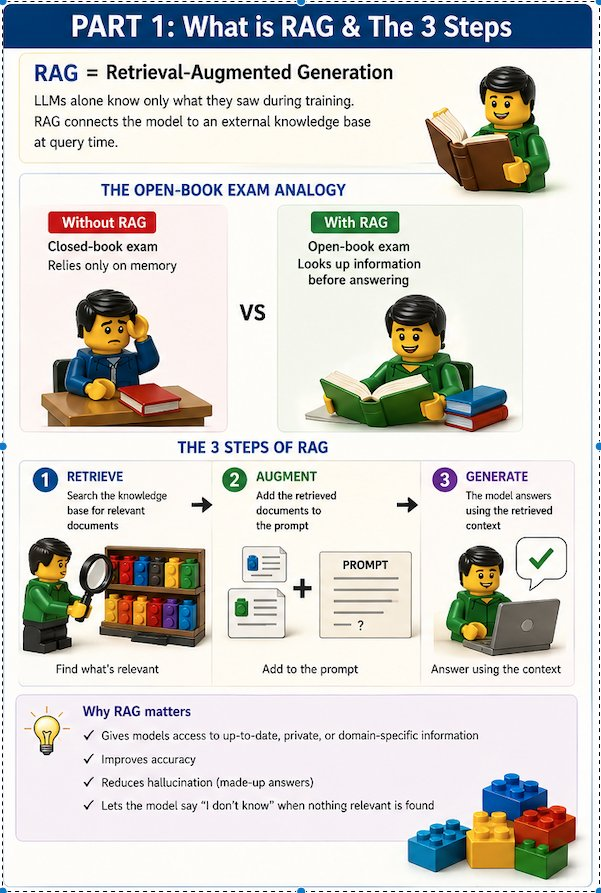

In [77]:
# 8A. Our knowledge base — in a real system this could be thousands of documents

knowledge_base = [
    "Python is a programming language often used for AI and automation.",
    "Embeddings turn text into numbers so we can compare meaning.",
    "RAG stands for Retrieval-Augmented Generation.",
    "Tokens are small pieces of text used by language models.",
    "A parameter is a learned numeric value inside a model.",
    "Attention allows a model to focus on the most relevant words in context.",
    "Training is the process of adjusting parameters to reduce the model's error.",
]

print("Knowledge base documents:")
for i, doc in enumerate(knowledge_base, start=1):
    print(f"  [{i}] {doc}")

Knowledge base documents:
  [1] Python is a programming language often used for AI and automation.
  [2] Embeddings turn text into numbers so we can compare meaning.
  [3] RAG stands for Retrieval-Augmented Generation.
  [4] Tokens are small pieces of text used by language models.
  [5] A parameter is a learned numeric value inside a model.
  [6] Attention allows a model to focus on the most relevant words in context.
  [7] Training is the process of adjusting parameters to reduce the model's error.


In [78]:

# ============================================================
# SECTION 7B — RETRIEVE: Find the Most Relevant Documents
# ============================================================
# When a user asks a question, we search the knowledge base
# for documents that SHARE THE MOST MEANINGFUL WORDS with the question.
#
# Score = number of meaningful words in BOTH the question AND the document.
# Higher score = more relevant document.
#
# We first remove "stop words" — extremely common words like "is", "a",
# "the", "of" — because they appear in almost every sentence and cause
# false matches. Real RAG systems do the same before scoring.
# ============================================================

# Words so common they carry no useful meaning for search.
# Without this filter: "What is a neural network?" would match
# "Python is a programming language..." on the words "is" and "a" —
# a completely wrong result!
STOP_WORDS = {
    "a", "an", "the", "is", "are", "was", "were", "to", "of", "in",
    "for", "on", "with", "at", "by", "and", "or", "but", "what",
    "how", "why", "when", "where", "which", "it", "its", "this",
    "that", "we", "i", "you", "he", "she", "they", "so", "not",
    "be", "been", "has", "have", "had", "do", "does", "did", "as",
    "called", "used", "s"
}

def retrieve_top_documents(question, documents, how_many=2):
    """
    Find the most relevant documents for a given question.

    How it works:
    1. Split the question into words and remove stop words (filler words)
    2. For each document, count how many of those meaningful words appear in it
    3. Return the top 'how_many' documents with the highest score
    """
    # Keep only meaningful words from the question
    question_words = set(simple_tokenize(question)) - STOP_WORDS

    if not question_words:
        return []   # nothing meaningful to search with

    results = []
    for doc in documents:
        doc_words = set(simple_tokenize(doc)) - STOP_WORDS
        # Count the overlap: meaningful words in BOTH the question AND the doc
        overlap_score = len(question_words & doc_words)
        results.append((overlap_score, doc))

    # Sort by score, highest first
    results.sort(reverse=True)

    # Return only documents that had at least 1 matching meaningful word
    return [(doc, score) for score, doc in results[:how_many] if score > 0]

# --- Test it with a sample question ---
question = "What is the process of adjusting parameters called?"

# ============================================================
# STEP-BY-STEP WALKTHROUGH
# ============================================================
print("❓ Question:", question)
print()

all_words      = set(simple_tokenize(question))
question_words = all_words - STOP_WORDS

print("Step 1 — Remove stop words, keep only meaningful words:")
print(f"  All words    : {sorted(all_words)}")
print(f"  After filter : {sorted(question_words)}  ← only these are used for scoring")
print()

print("Step 2 — Score every document by counting shared meaningful words:")
print("-" * 65)

max_score = max(
    len(question_words & (set(simple_tokenize(d)) - STOP_WORDS))
    for d in knowledge_base
)

for doc in knowledge_base:
    doc_words     = set(simple_tokenize(doc)) - STOP_WORDS
    shared_words  = question_words & doc_words
    overlap_score = len(shared_words)
    marker = "  ← TOP MATCH" if overlap_score == max_score and overlap_score > 0 else ""
    print(f"  Document : {doc}")
    print(f"  Doc words: {sorted(doc_words)}")
    print(f"  Shared   : {sorted(shared_words)}  →  Score = {overlap_score}{marker}")
    print()

print("-" * 65)
print()

# --- Now retrieve and display the final top results ---
found_docs = retrieve_top_documents(question, knowledge_base, how_many=2)

print("🔍 Top documents selected (highest overlap score wins):")
for doc, score in found_docs:
    print(f"  Score {score} shared word(s) → {doc}")
print()
print("The document with the highest overlap score is used as context.")


❓ Question: What is the process of adjusting parameters called?

Step 1 — Remove stop words, keep only meaningful words:
  All words    : ['adjusting', 'called', 'is', 'of', 'parameters', 'process', 'the', 'what']
  After filter : ['adjusting', 'parameters', 'process']  ← only these are used for scoring

Step 2 — Score every document by counting shared meaningful words:
-----------------------------------------------------------------
  Document : Python is a programming language often used for AI and automation.
  Doc words: ['ai', 'automation', 'language', 'often', 'programming', 'python']
  Shared   : []  →  Score = 0

  Document : Embeddings turn text into numbers so we can compare meaning.
  Doc words: ['can', 'compare', 'embeddings', 'into', 'meaning', 'numbers', 'text', 'turn']
  Shared   : []  →  Score = 0

  Document : RAG stands for Retrieval-Augmented Generation.
  Doc words: ['augmented', 'generation', 'rag', 'retrieval', 'stands']
  Shared   : []  →  Score = 0

  Document 

In [79]:

# ============================================================
# SECTION 7C — AUGMENT: Build the Prompt Sent to the Model
# ============================================================
# This is the "Augment" step of RAG.
# We take the user's question AND the retrieved documents,
# and combine them into a single text block called a PROMPT.
#
# This prompt is what actually gets sent to the language model.
# By including the relevant documents, we give the model the
# information it needs to answer accurately — even if the topic
# was not in its training data.
# ============================================================

def build_rag_prompt(question, retrieved_docs):
    """
    Combine the retrieved documents with the user's question
    into a single prompt for the language model.
    """
    # Format each retrieved document as a bullet point
    context_lines = "\n".join(f"  • {doc}" for doc, _ in retrieved_docs)

    # Build the full prompt as plain text
    prompt = (
        "You are a helpful assistant.\n"
        "Answer the question using ONLY the information in the context below.\n"
        "Do not make up any information.\n"
        "\n"
        "--- CONTEXT (retrieved from knowledge base) ---\n"
        f"{context_lines}\n"
        "------------------------------------------------\n"
        "\n"
        f"Question: {question}\n"
        "\n"
        "Answer:"
    )
    return prompt

# --- Build and display the prompt ---
prompt = build_rag_prompt(question, found_docs)

print("📋 Full prompt sent to the language model:")
print("=" * 60)
print(prompt)
print("=" * 60)
print()
print("👆 Notice how the model is given the answer through context.")
print("   It does NOT need to have memorised anything — the answer is in the context.")
print("   This is the power of RAG.")


📋 Full prompt sent to the language model:
You are a helpful assistant.
Answer the question using ONLY the information in the context below.
Do not make up any information.

--- CONTEXT (retrieved from knowledge base) ---
  • Training is the process of adjusting parameters to reduce the model's error.
------------------------------------------------

Question: What is the process of adjusting parameters called?

Answer:

👆 Notice how the model is given the answer through context.
   It does NOT need to have memorised anything — the answer is in the context.
   This is the power of RAG.


In [41]:

# ============================================================
# SECTION 7D — GENERATE: Full RAG Pipeline in Action
# ============================================================
# This ties everything together:
#   1. RETRIEVE the most relevant document for a question
#   2. AUGMENT (we skip printing the full prompt here, just show the answer)
#   3. GENERATE a response based on what was retrieved
#
# Since we have no real LLM here, we simulate the "generate" step
# by returning the best retrieved document as the answer.
# A real LLM would produce a fluent, natural-language sentence instead.
# ============================================================

def rag_answer(question, documents):
    """
    Full RAG pipeline:
    - Retrieve the best matching document
    - Return it as the answer (simulated generation)
    """
    matches = retrieve_top_documents(question, documents, how_many=1)

    if not matches:
        # Nothing relevant found in our knowledge base
        return "❌ I could not find relevant information in the knowledge base."

    best_document, score = matches[0]
    return f"✅ Based on the knowledge base: {best_document}"

# --- Test with several questions ---
test_questions = [
    "What is RAG?",
    "What are tokens?",
    "How does attention work?",
    "What is training?",
    "What is a neural network?"   # this one is NOT in our knowledge base
]

print("Testing the full RAG pipeline:")
print("=" * 65)
for q in test_questions:
    print(f"❓ {q}")
    print(f"   {rag_answer(q, knowledge_base)}")
    print("-" * 65)

print()
print("Notice the last question about 'neural network':")
print("It is NOT in our knowledge base, so RAG honestly says: 'I don't know.'")
print()

# ============================================================
# 🚨 BONUS: HALLUCINATION DEMO
# ============================================================
# What happens when a model has NO knowledge base to refer to
# and still tries to answer?  It MAKES SOMETHING UP.
# This is called HALLUCINATION — the model sounds confident
# but the answer is completely wrong.
#
# Below we simulate this to show WHY RAG matters.
# ============================================================

hallucinated_responses = [
    "A neural network is a type of spreadsheet formula system originally developed by Microsoft Excel to handle recursive financial calculations.",
    "A neural network is a communication standard invented by Cisco in 1994 to route internet traffic between data centres.",
    "A neural network is a database schema architecture used by Oracle to store medical records in a tree-like structure.",
    "A neural network is a compression algorithm used in MP3 audio files to remove frequencies the human ear cannot detect.",
    "A neural network is a hardware component inside a graphics card that accelerates 3D rendering for video games.",
]

print("=" * 65)
print("🚨 HALLUCINATION DEMO — What if there was NO RAG?")
print("=" * 65)
print()
print("❓ What is a neural network?")
print()
print("   With RAG    → ❌ I could not find relevant information.")
print("                  (Honest — it knows what it does NOT know)")
print()
print("   Without RAG → the model guesses and sounds VERY confident:")
print()

random.seed()   # use a different seed each run so the answer is random
fake_answer = random.choice(hallucinated_responses)
print(f'   🤖 "' + fake_answer + '"')
print()
print("⚠️  That answer sounds plausible — but it is 100% made up!")
print("   This is hallucination: the model fabricates a confident,")
print("   fluent answer with no factual basis.")
print()
print("💡 KEY LESSON:")
print("   RAG prevents hallucination by forcing the model to answer")
print("   ONLY from retrieved documents — or admit it does not know.")
print("   No document found = no answer. Simple, but powerful.")


Testing the full RAG pipeline:
❓ What is RAG?
   ✅ Based on the knowledge base: RAG stands for Retrieval-Augmented Generation.
-----------------------------------------------------------------
❓ What are tokens?
   ✅ Based on the knowledge base: Tokens are small pieces of text used by language models.
-----------------------------------------------------------------
❓ How does attention work?
   ✅ Based on the knowledge base: Attention allows a model to focus on the most relevant words in context.
-----------------------------------------------------------------
❓ What is training?
   ✅ Based on the knowledge base: Training is the process of adjusting parameters to reduce the model's error.
-----------------------------------------------------------------
❓ What is a neural network?
   ❌ I could not find relevant information in the knowledge base.
-----------------------------------------------------------------

Notice the last question about 'neural network':
It is NOT in our knowled

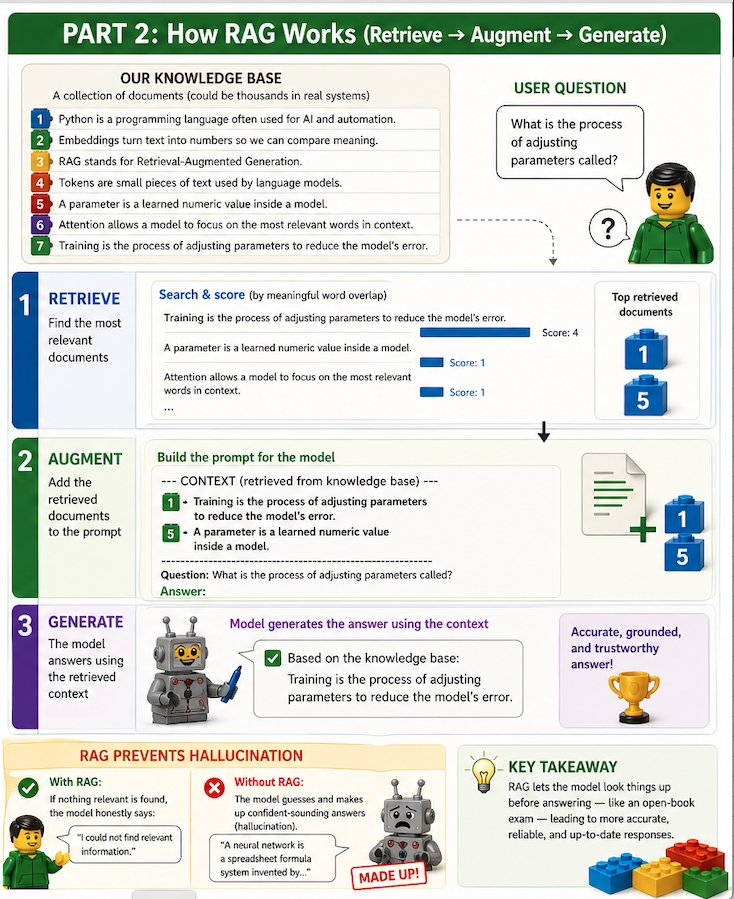

### Why RAG matters in practice

| Without RAG | With RAG |
|---|---|
| Model knows only training data | Model can use fresh, private documents |
| May hallucinate outdated facts | Answers are grounded in retrieved sources |
| Cannot reference your data | Can reference your internal knowledge base |
| Hard to audit | You can point to the source document |

RAG is one of the most widely deployed GenAI patterns in enterprise applications today.

---
# 8. Agents & MCP — The AI That Takes Action

So far, everything in this notebook has been **reactive**.

You ask → the AI thinks → the AI answers.

Even with RAG, the AI is still only *reading* — it looks up documents, then speaks.

But what happens when you need the AI to actually ***do*** something?

---

## The Personal Assistant Analogy

Imagine you have just hired a brilliant personal assistant called Alex.

**Week 1** — Alex can answer questions from memory. Great for general knowledge.

**Week 2** — You give Alex access to the company filing cabinet (RAG). Now Alex can look things up before answering.

**Week 3** — You give Alex a bigger job:

> *"Alex, check the weather in London, calculate our Q3 budget, and look up what RAG stands for."*

Suddenly, reading and answering is not enough. Alex needs to **take actions**:
- Call the weather service
- Run a calculation
- Search the knowledge base

This is what an **Agent** does. An agent is an AI that can:
1. **Think** about what action is needed
2. **Choose** the right tool from its toolbox
3. **Call** that tool and get a result
4. **Decide** what to do next based on the result

---

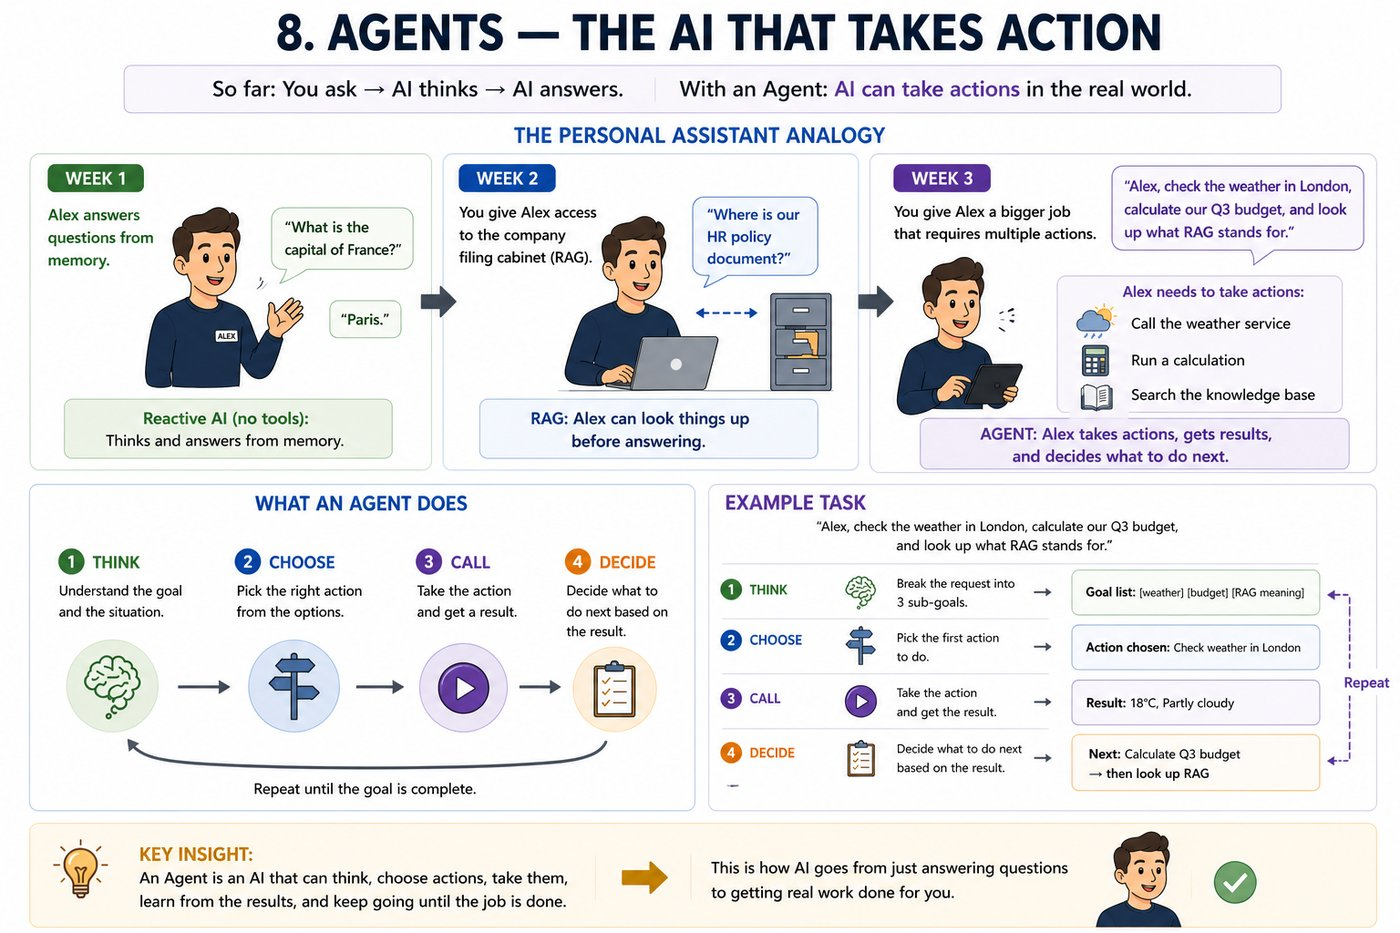

## What is a Tool?

A tool is simply a **function the agent is allowed to call**.

- `get_weather("London")` → returns current weather
- `calculate("15 * 24")` → returns 360
- `search_knowledge_base("What is RAG?")` → returns a document

The agent does not run all tools blindly. It *reads the task*, *picks the right tool*, and *passes the right input*. Like Alex deciding whether to call the weather service or open the filing cabinet.

---

## What is MCP?

**MCP (Model Context Protocol)** is the universal standard that describes *what tools are available* and *how to call them*.

Think of it as the **company phone directory** that every new employee (every AI) can read:

```
Tool: get_weather
  → What it does: Get the current weather for a city
  → What to give it: a city name

Tool: search_knowledge_base
  → What it does: Search documents for an answer
  → What to give it: a question

Tool: calculate
  → What it does: Evaluate a maths expression
  → What to give it: something like "15 * 24"
```

Before AI existed, every application had to hard-code its integrations. With MCP, you write a tool *once*, describe it in a standard format, and *any* AI that speaks MCP can discover and use it automatically.

> **Key message:** RAG gave the AI a library card. Agents give it a Swiss Army knife. MCP is the label on each blade so the AI always knows which one to pick up.

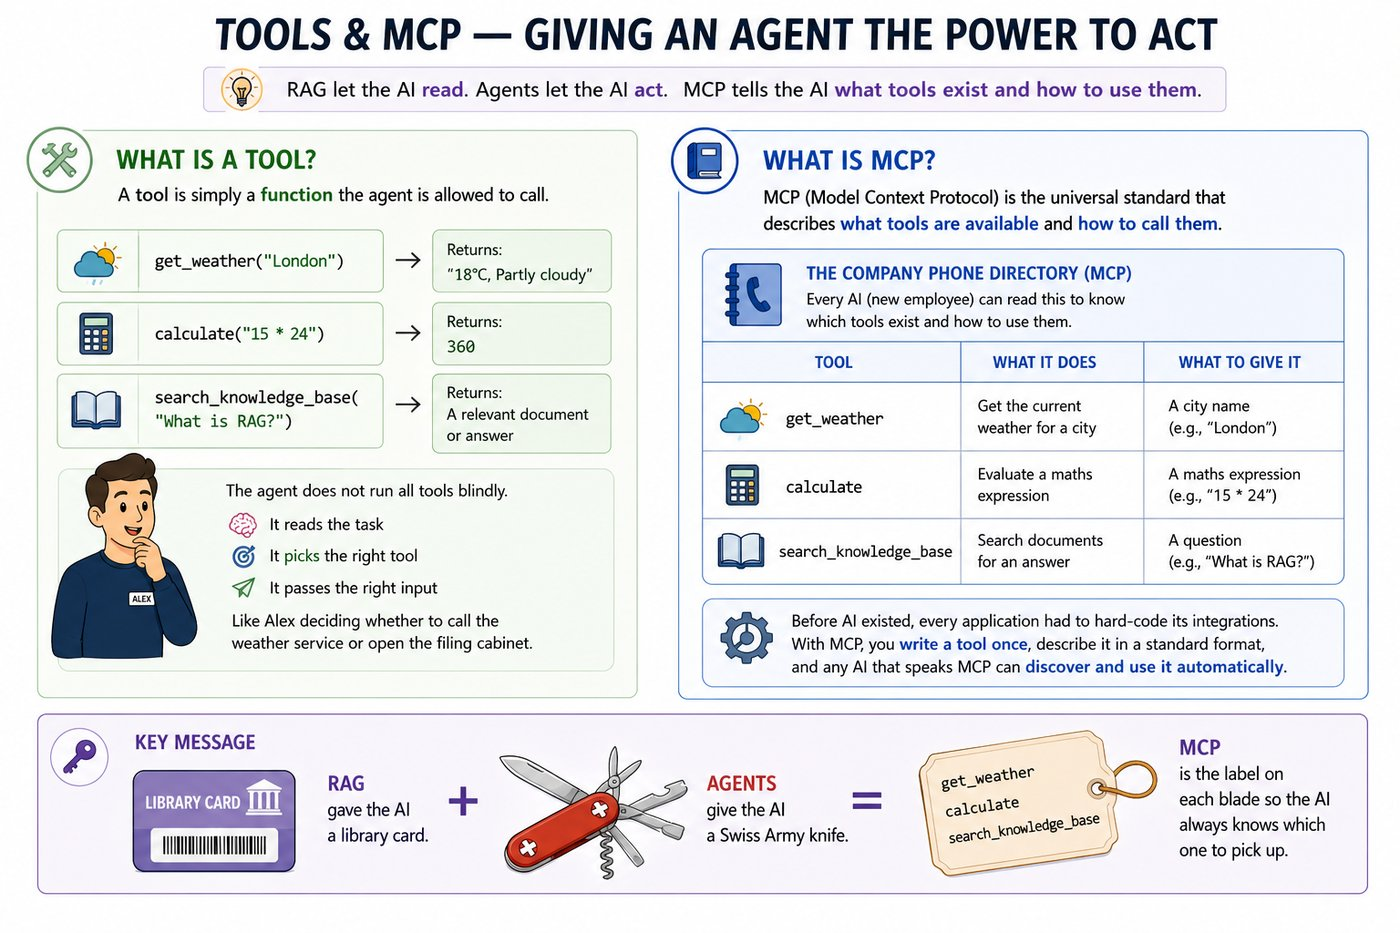

In [80]:

# ============================================================
# SECTION 8 — AGENTS & MCP: The AI That Takes Action
# ============================================================
# We build three things here:
#
#   1. TOOLS — simple Python functions the agent can call
#   2. MCP TOOL REGISTRY — a directory describing each tool
#      (this is the heart of the Model Context Protocol idea)
#   3. AGENT LOOP — reads the task, picks a tool, calls it,
#      returns the result
#
# In a real system the LLM itself decides which tool to pick.
# Here we use keyword matching — same concept, no LLM needed.
# ============================================================

# ---- Step 1: Define Tools ----
# Each tool is just a Python function.
# In a real agent system these would call real APIs.

def get_weather(city):
    """Tool: look up the current weather for a city."""
    # Simulated data — a real tool would call a weather API
    weather_data = {
        "london":    "☁️  Cloudy, 14°C",
        "new york":  "🌤  Partly sunny, 22°C",
        "tokyo":     "🌧  Rainy, 18°C",
        "sydney":    "☀️  Sunny, 27°C",
        "paris":     "🌥  Overcast, 16°C",
    }
    return weather_data.get(city.strip().lower(), "❓ No weather data for that city.")

def search_knowledge_base(query):
    """Tool: search the RAG knowledge base from Section 7."""
    docs = retrieve_top_documents(query, knowledge_base, how_many=1)
    if docs:
        return docs[0][0]
    return "❌ Nothing relevant found in the knowledge base."

def calculate(expression):
    """Tool: safely evaluate a simple maths expression."""
    # Only allow digits and basic operators — never eval untrusted input
    allowed = set("0123456789 +-*/(). ")
    if not all(c in allowed for c in expression):
        return "❌ Only basic arithmetic is supported (digits and + - * / brackets)."
    try:
        result = eval(expression)   # safe here: we checked every character above
        return f"{expression.strip()} = {result}"
    except Exception:
        return "❌ Could not evaluate that expression."

# ---- Step 2: The MCP Tool Registry ----
# MCP = a standardised description of every tool the agent can use.
# The agent checks this registry BEFORE taking any action,
# just like Alex checking the company phone directory.

MCP_TOOLS = {
    "get_weather": {
        "description": "Get the current weather for a city",
        "input_hint":  "a city name, e.g. 'London'",
        "function":    get_weather,
        "keywords":    ["weather", "temperature", "forecast", "hot", "cold", "raining"],
    },
    "calculate": {
        "description": "Evaluate a simple maths expression",
        "input_hint":  "an expression like '15 * 24' or '(100 - 42) / 2'",
        "function":    calculate,
        "keywords":    ["calculate", "compute", "multiply", "divide", "plus", "minus",
                        "+", "-", "*", "/", "how much is", "what is"],
    },
    "search_knowledge_base": {
        "description": "Search the knowledge base for an answer",
        "input_hint":  "a question or topic",
        "function":    search_knowledge_base,
        "keywords":    [],  # default fallback tool
    },
}

print("🔧 MCP Tool Registry — tools available to the agent:")
print()
for name, info in MCP_TOOLS.items():
    print(f"  📌 {name}")
    print(f"     What it does : {info['description']}")
    print(f"     What to pass : {info['input_hint']}")
    print()

# ---- Step 3: The Agent Loop ----
# The agent:
#   1. Reads the task
#   2. Checks the MCP registry for matching tools
#   3. Calls the best-matching tool
#   4. Returns the result

def run_agent(task):
    """
    A minimal AI agent that resolves a task using the MCP tool registry.

    Decision rule: scan the task for each tool's keywords.
    The tool with the most keyword matches wins.
    If no keywords match, fall back to searching the knowledge base.
    """
    task_lower = task.lower()
    print(f"📥 Task : '{task}'")

    # Score every tool by counting keyword matches
    scores = {}
    for tool_name, info in MCP_TOOLS.items():
        scores[tool_name] = sum(1 for kw in info["keywords"] if kw in task_lower)

    chosen_tool = max(scores, key=scores.get)

    # --- Extract the relevant input for the chosen tool ---
    if chosen_tool == "get_weather":
        # Take the last word as the city name (simple heuristic)
        tool_input = task.split()[-1].rstrip("?.")
    elif chosen_tool == "calculate":
        # Everything after "calculate", "compute", or "what is"
        tool_input = task_lower
        for trigger in ["calculate", "compute", "what is", "how much is"]:
            if trigger in task_lower:
                tool_input = task_lower.split(trigger)[-1].strip().rstrip("?.")
                break
    else:
        tool_input = task   # use the full task as the search query

    tool_info = MCP_TOOLS[chosen_tool]
    print(f"🔍 Agent chose tool : '{chosen_tool}'")
    print(f"   ({tool_info['description']})")
    print(f"   Passing input    : '{tool_input}'")

    result = tool_info["function"](tool_input)
    print(f"✅ Result : {result}")
    print()
    return result

# ---- Test the agent with several tasks ----
test_tasks = [
    "What is the weather in Tokyo?",
    "Calculate 15 * 24",
    "What is RAG?",
    "What is training?",
    "What is the weather in Sydney?",
    "What is a neural network?",    # not in knowledge base — honest failure
]

print("=" * 60)
print("🤖 AGENT IN ACTION")
print("=" * 60)
print()
for task in test_tasks:
    run_agent(task)
    print("-" * 60)
    print()

print("💡 KEY INSIGHT:")
print("   The agent does NOT answer from memory.")
print("   It reads the task, consults the MCP registry,")
print("   picks the right tool, and returns a grounded result.")
print()
print("   In a real AI agent system (like GitHub Copilot, Cursor,")
print("   or Claude with tools), the LLM itself reads the MCP")
print("   registry and decides which tool to call — automatically.")


🔧 MCP Tool Registry — tools available to the agent:

  📌 get_weather
     What it does : Get the current weather for a city
     What to pass : a city name, e.g. 'London'

  📌 calculate
     What it does : Evaluate a simple maths expression
     What to pass : an expression like '15 * 24' or '(100 - 42) / 2'

  📌 search_knowledge_base
     What it does : Search the knowledge base for an answer
     What to pass : a question or topic

🤖 AGENT IN ACTION

📥 Task : 'What is the weather in Tokyo?'
🔍 Agent chose tool : 'get_weather'
   (Get the current weather for a city)
   Passing input    : 'Tokyo'
✅ Result : 🌧  Rainy, 18°C

------------------------------------------------------------

📥 Task : 'Calculate 15 * 24'
🔍 Agent chose tool : 'calculate'
   (Evaluate a simple maths expression)
   Passing input    : '15 * 24'
✅ Result : 15 * 24 = 360

------------------------------------------------------------

📥 Task : 'What is RAG?'
🔍 Agent chose tool : 'calculate'
   (Evaluate a simple maths e

---
## 8B. Agents That Need a Sign-off — Guardrails

In Section 8, the agent called every tool straight away. That is fine for tools that only **read** something, like checking the weather or searching documents. If the agent picks the wrong one, you get a wrong answer, and you can simply ignore it.

Now imagine tools that **change** something in the real world: sending an email, paying a bill, deleting a file, booking a meeting. If the agent gets one of those wrong, you can't take it back.

That is why real agent apps add a **guardrail**: before a risky action, the agent stops and asks a person. You have probably seen this as an "Allow" / "Deny" button, or a question like "Shall I send this?"

## The New Intern Analogy

Think of a new intern in their first week:
- They can **look things up** on their own: check the calendar, read a report, find a phone number.
- But before they **email a client** or **spend company money**, they check with you first.

You don't stop them doing the work. You only ask them to check with you before anything that can't be undone.

## Two Kinds of Tools

| | Reads something | Changes something |
|---|---|---|
| **Examples** | Check the weather, search documents, calculate | Send an email, make a payment, delete a file |
| **If the agent gets it wrong** | A wrong answer you can ignore | A mistake you can't take back |
| **Guardrail** | Runs on its own | Waits for a person to say yes |

In [82]:
# ============================================================
# SECTION 8B — GUARDRAILS: Ask a Person Before Risky Actions
# ============================================================
# We add one new tool to the MCP registry from Section 8:
# send_email. Unlike the other tools, it CHANGES something
# in the real world, so we label it "needs_approval": True.
#
# Then we put a guardrail on every tool with that label:
# it pauses and waits until a person says yes.
# The agent from Section 8 is not changed at all.
# ============================================================

def send_email(message):
    """Tool: send an email (simulated, nothing is really sent)."""
    return f"📧 Email sent: '{message}'"

MCP_TOOLS["send_email"] = {
    "description":    "Send an email on the user's behalf",
    "input_hint":     "the message to send",
    "function":       send_email,
    "keywords":       ["email", "send", "mail"],
    "needs_approval": True,
}

# Tools a person has said yes to. In a real app, this is the
# "Allow" button the person clicks.
approved_by_person = set()

def ask_a_person_first(tool_name, tool_function):
    """Wrap a tool so it only runs after a person says yes."""
    def guarded_tool(tool_input):
        if tool_name not in approved_by_person:
            return f"⏸ Paused: '{tool_name}' changes something in the real world. Waiting for a person to approve."
        approved_by_person.discard(tool_name)   # one yes = one action
        return tool_function(tool_input)
    return guarded_tool

# Put the guardrail on every tool labelled "needs_approval"
for name, info in MCP_TOOLS.items():
    if info.get("needs_approval") and not info.get("has_guardrail"):
        info["function"] = ask_a_person_first(name, info["function"])
        info["has_guardrail"] = True

print("🔐 Which tools need a person's OK?")
for name, info in MCP_TOOLS.items():
    rule = "needs approval" if info.get("needs_approval") else "runs on its own"
    print(f"   {name:<22} → {rule}")
print()

email_task = "Send an email to the team saying the report is ready"

print("=" * 60)
print("1️⃣  A tool that only READS: the agent goes ahead on its own")
print("=" * 60)
run_agent("Check the weather in London")

print("=" * 60)
print("2️⃣  A tool that CHANGES something: the agent has to wait")
print("=" * 60)
run_agent(email_task)

print("=" * 60)
print("3️⃣  The person clicks 'Allow', and the agent tries again")
print("=" * 60)
approved_by_person.add("send_email")
run_agent(email_task)

print("=" * 60)
print("4️⃣  One yes covers one action: the next email needs a new yes")
print("=" * 60)
run_agent(email_task)

🔐 Which tools need a person's OK?
   get_weather            → runs on its own
   calculate              → runs on its own
   search_knowledge_base  → runs on its own
   send_email             → needs approval

1️⃣  A tool that only READS: the agent goes ahead on its own
📥 Task : 'Check the weather in London'
🔍 Agent chose tool : 'get_weather'
   (Get the current weather for a city)
   Passing input    : 'London'
✅ Result : ☁️  Cloudy, 14°C

2️⃣  A tool that CHANGES something: the agent has to wait
📥 Task : 'Send an email to the team saying the report is ready'
🔍 Agent chose tool : 'send_email'
   (Send an email on the user's behalf)
   Passing input    : 'Send an email to the team saying the report is ready'
✅ Result : ⏸ Paused: 'send_email' changes something in the real world. Waiting for a person to approve.

3️⃣  The person clicks 'Allow', and the agent tries again
📥 Task : 'Send an email to the team saying the report is ready'
🔍 Agent chose tool : 'send_email'
   (Send an email on 

### What you just saw

- **Checking the weather** only reads something, so the agent went ahead on its own.
- **Sending an email** changes something, so the tool paused and waited. The agent didn't break: it handed the decision back to a person.
- Once the person said yes, the email went out. The next email needed a new yes, because **one approval covers one action**.

The agent code from Section 8 didn't change at all. The guardrail sits around the tool, and it's switched on by one label in the MCP registry: `"needs_approval": True`. Real agent apps work the same way, which is why you see "Allow" / "Deny" buttons when an AI wants to send, pay, book or delete something for you. The more an agent can do, the more this matters.

> **Try it:** in the cell above, add `MCP_TOOLS["calculate"]["needs_approval"] = True` just before the line `# Put the guardrail on every tool labelled "needs_approval"`. Run the cell, then run `run_agent("Calculate 15 * 24")`. Which tools in your own work would you want an AI to check with you about first?

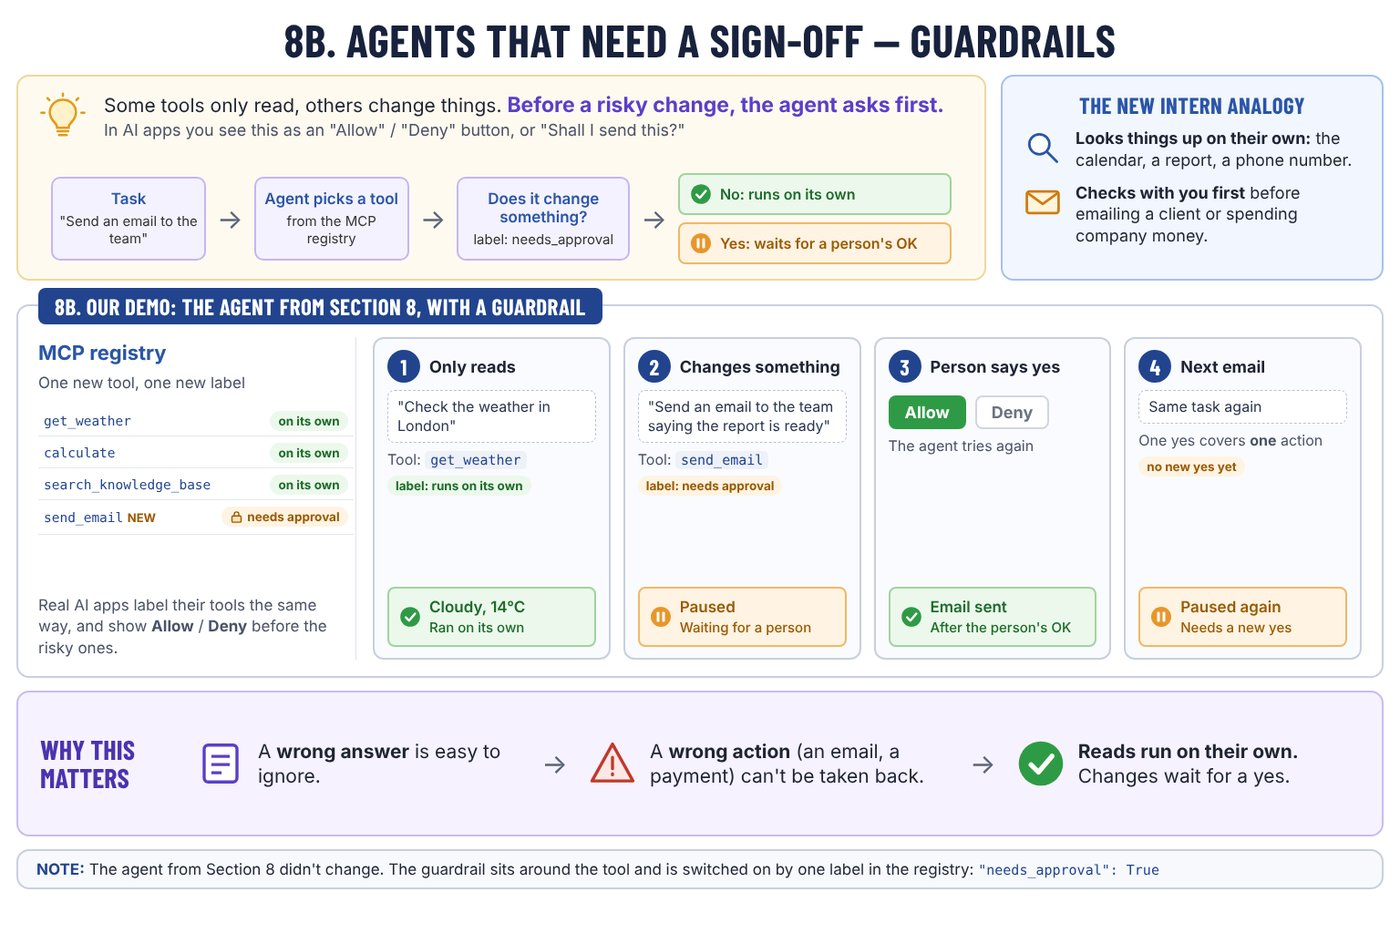

---
## 8C. Decision Models — AI That Picks Instead of Writing

Everything so far has been about models that **write**: they produce text one token at a time (Section 5).

A newer kind of model does something simpler. You give it a question and a **fixed list of allowed answers**, and it gives back a **score for each answer**. It doesn't write anything. These are called **decision models**, and models like Microsoft's Decision-1 and TypeSafe's Jev appeared in 2026.

Because they only pick from a list, they are very fast and cheap. That makes them a good fit for the small pick-one decisions an AI app makes all day: Which team should get this ticket? Is this message about billing? Should the agent go ahead, or ask a person first?

## The Post Office Sorter Analogy

A post office sorter doesn't write letters. They look at each letter and drop it into the right box, very quickly. When an address is unclear, they don't guess: they put the letter aside for someone to check.

A decision model is the sorter. A writing model is the person who writes the letters.

## Writing Model vs Decision Model

| | Writing model (LLM) | Decision model |
|---|---|---|
| **You give it** | A question | A question and a fixed list of answers |
| **You get back** | Text | A score for each answer |
| **Speed and cost** | Slower, costs more | Very fast, very cheap |
| **Good for** | Explaining, drafting, chatting | Sorting, routing, yes/no checks |

In [83]:
# ============================================================
# SECTION 8C — DECISION MODELS: Pick From a Fixed List
# ============================================================
# A decision model doesn't write. It gets a question and a fixed
# list of allowed answers, and gives back a score for each one.
#
# Here the question is: "Which team should handle this ticket?"
# The allowed answers are: billing, tech, delivery.
#
# Our tiny decision model scores each team by counting clue
# words, then turns the scores into percentages with softmax
# (the same helper we used for attention in Section 4).
# If it is sure enough, it acts. If not, it asks a person,
# just like the guardrail in Section 8B.
# ============================================================

TEAMS = {
    "billing":  ["refund", "charged", "invoice", "payment"],
    "tech":     ["error", "crash", "login", "password"],
    "delivery": ["late", "parcel", "tracking", "delivered"],
}
SURE_ENOUGH = 0.75   # act only when the top answer is at least 75%

def decide_team(ticket):
    """Give every allowed answer a score, as percentages that add up to 100%."""
    words = set(simple_tokenize(ticket))
    scores = [2 * sum(clue in words for clue in clues) for clues in TEAMS.values()]
    chances = dict(zip(TEAMS, softmax(scores)))
    best_team = max(chances, key=chances.get)
    return best_team, chances

tickets = [
    "I was charged twice, please refund my payment",
    "The app shows an error after login",
    "My parcel is late and tracking is stuck",
    "I was charged, but my order was never delivered",
    "Hello, I have a question about my account",
]

for ticket in tickets:
    best_team, chances = decide_team(ticket)
    print(f"🎫 Ticket: '{ticket}'")
    for team, chance in chances.items():
        bar_chart(team, chance)
    if chances[best_team] >= SURE_ENOUGH:
        print(f"   ✅ Sure enough ({chances[best_team]:.0%}): send to {best_team}")
    else:
        print(f"   ✋ Not sure ({chances[best_team]:.0%}): ask a person")
    print()

🎫 Ticket: 'I was charged twice, please refund my payment'
  billing          |#############################-| 0.995
  tech             |------------------------------| 0.002
  delivery         |------------------------------| 0.002
   ✅ Sure enough (100%): send to billing

🎫 Ticket: 'The app shows an error after login'
  billing          |------------------------------| 0.018
  tech             |############################--| 0.965
  delivery         |------------------------------| 0.018
   ✅ Sure enough (96%): send to tech

🎫 Ticket: 'My parcel is late and tracking is stuck'
  billing          |------------------------------| 0.002
  tech             |------------------------------| 0.002
  delivery         |#############################-| 0.995
   ✅ Sure enough (100%): send to delivery

🎫 Ticket: 'I was charged, but my order was never delivered'
  billing          |##############----------------| 0.468
  tech             |#-----------------------------| 0.063
  delivery         |##

### What you just saw

- The **clear tickets** got one high score, so they went straight to the right team.
- The ticket about **a charge and a missing delivery** split its score between two teams (47% each), so it went to a person.
- The **vague ticket** gave every team the same score (33%), so it also went to a person.

That's the useful part of a decision model. A writing model gives you text, and it's hard to tell how sure it is. A decision model gives you a score for every answer, so you can set a simple rule: act when it's sure, and ask a person when it isn't. It's the same guardrail idea as Section 8B, now driven by a score.

> **Honest note:** real decision models read the whole message, the way a language model does. They don't just count clue words. Our demo only shows the idea: pick from a fixed list, with a score, and ask a person when unsure.

> **Try it:** change `SURE_ENOUGH` to `0.5`, then to `0.99`, and run the cell again. Which tickets go to a person now? Then add a `"returns"` team to `TEAMS` with its own clue words, and write a ticket for it.

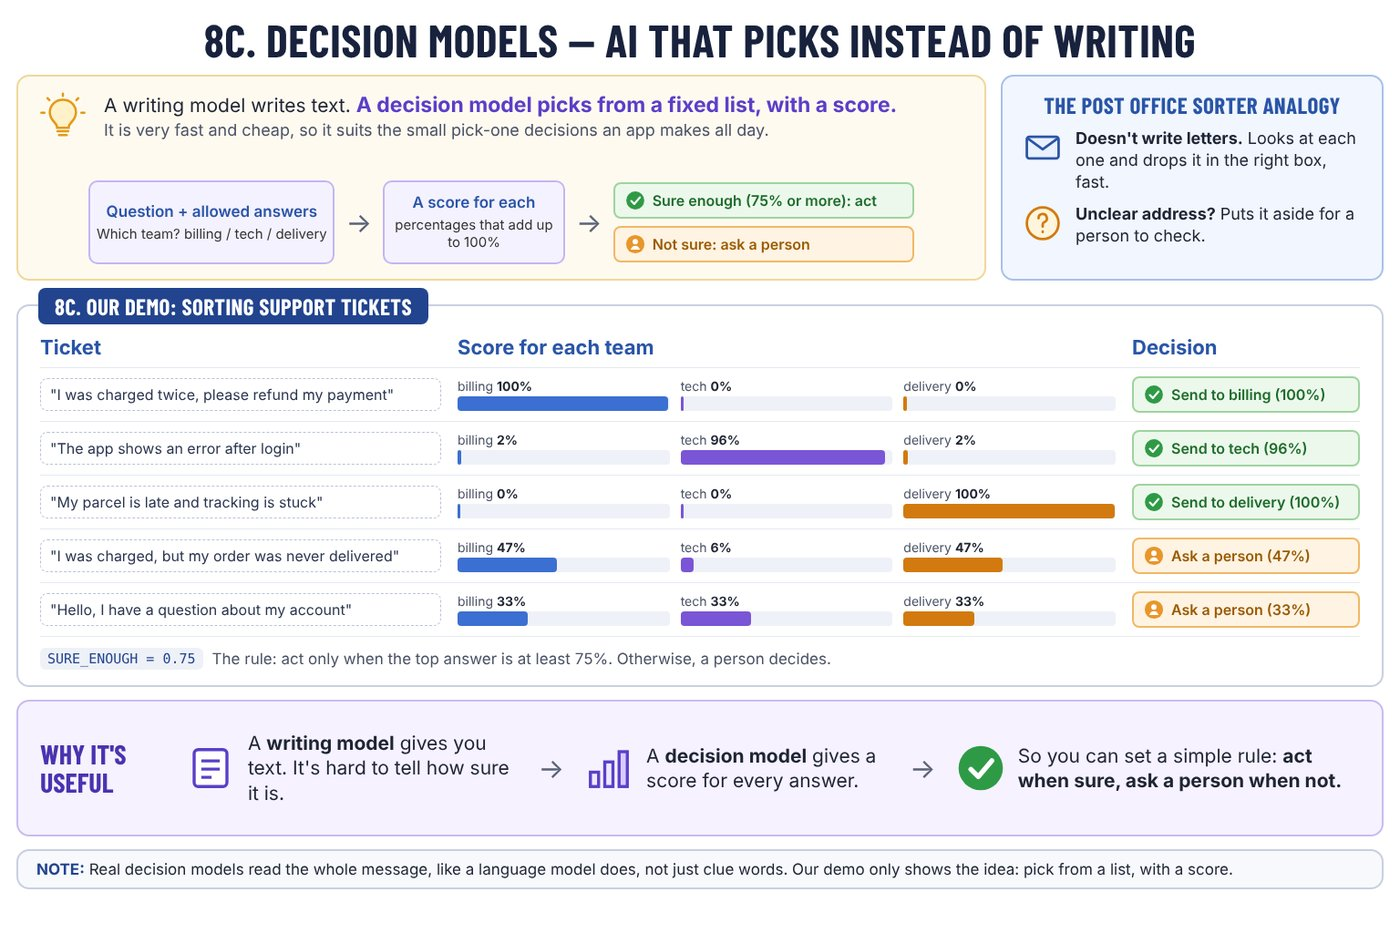

---
# 9. The Full Picture

Everything you have learned in this workshop — tokens, embeddings, attention, parameters, training, RAG, and agents — comes together every time you type a message to an AI.

Here is the complete journey, from your words to the model's response:

```
╔══════════════════════════════════════════════════════════════╗
║           YOU TYPE:  "What is machine learning?"            ║
╚══════════════════════════════════════════════════════════════╝
                              │
              ╔═══════════════▼════════════════╗
              ║       AGENT: CHOOSE ACTION     ║  ← Section 8
              ║  Read task, check MCP registry ║
              ║  → pick the right tool         ║
              ╚═══════════════╤════════════════╝
                              │
              ╔═══════════════▼════════════════╗
              ║         RAG: RETRIEVE          ║  ← Section 7
              ║  Search knowledge base for     ║
              ║  relevant documents            ║
              ║  "Machine learning is..."  ✅  ║
              ╚═══════════════╤════════════════╝
                              │  (retrieved context added to prompt)
              ╔═══════════════▼════════════════╗
              ║       TOKENISE & ENCODE        ║  ← Section 1
              ║  Text  →  Token IDs (numbers)  ║
              ║  "what" → 482,  "is" → 317 ... ║
              ╚═══════════════╤════════════════╝
                              │
              ╔═══════════════▼════════════════╗
              ║        EMBEDDING LOOKUP        ║  ← Section 3
              ║  Each token ID →               ║
              ║  a rich vector of numbers      ║
              ║  that captures its meaning     ║
              ╚═══════════════╤════════════════╝
                              │
              ╔═══════════════▼════════════════╗
              ║        ATTENTION LAYERS        ║  ← Section 4
              ║  Every token asks:             ║
              ║  "Which other words matter     ║
              ║   most to ME right now?"       ║
              ╚═══════════════╤════════════════╝
                              │
              ╔═══════════════▼════════════════╗
              ║      PARAMETER COMPUTATION     ║  ← Sections 2 & 6
              ║  Billions of                   ║
              ║  weight × input + bias         ║
              ║  steps, running in parallel    ║
              ╚═══════════════╤════════════════╝
                              │
              ╔═══════════════▼════════════════╗
              ║      NEXT TOKEN PREDICTION     ║  ← Section 5
              ║  Pick the most likely          ║
              ║  next word from the vocabulary ║
              ╚═══════════════╤════════════════╝
                              │
              ╔═══════════════▼════════════════╗
              ║         REPEAT UNTIL DONE      ║
              ║  Predicted token → new input   ║
              ║  Predict again... and again... ║
              ╚═══════════════╤════════════════╝
                              │
╔══════════════════════════════▼═══════════════════════════════╗
║         RESPONSE:  "Machine learning is the process of..."  ║
╚══════════════════════════════════════════════════════════════╝
```

---

## Every concept — one line each

| Step | Concept | What happens |
|------|---------|-------------|
| 0 | **Agent** | Reads the task, decides which tool to use, and asks a person before risky actions |
| 0 | **MCP** | The tool registry the agent consults before acting |
| 0 | **Decision model** | Makes quick pick-one choices with a score, and hands unsure ones to a person |
| 0 | **RAG** | Relevant documents are fetched and added to the prompt |
| 1 | **Tokens** | Your text is broken into numbered pieces |
| 2 | **Embeddings** | Each number becomes a rich vector encoding meaning |
| 3 | **Attention** | Each token decides which other tokens matter most |
| 4 | **Parameters** | Billions of learned numbers transform vectors into a prediction |
| 5 | **Next-token prediction** | The most likely next word is chosen |
| 6 | **Repeat** | Steps 3–5 repeat until the full response is generated |

> **Without RAG or Agents** — the model answers from memory alone and may hallucinate.  
> **With RAG** — the model reads your documents first. Grounded, accurate, auditable.  
> **With Agents + MCP** — the model can act on your behalf, calling any tool you give it.  
> **With a thinking model** — on harder questions, the model writes out its working before the final answer. Slower, but fewer mistakes.


---
# 10. Mini Challenges

Try these on your own to solidify your understanding:

### Challenge 1 — Tokens
Add a sentence full of punctuation (e.g. `"Hello, world! Is this... working?"`) and inspect the token list.

### Challenge 2 — Parameters
In the `tiny_model` cell, find a weight and bias such that for inputs 1, 2, 3 the outputs are 4, 7, 10.  
*(Hint: think about the pattern y = ?x + ?)*

### Challenge 3 — Embeddings
Add two new sentences to the `sentences` list in Section 3.  
Use `bag_of_words` and `cosine_similarity` to find which pair is most similar.

### Challenge 4 — Attention
Create a new sentence where the word `"light"` could mean either a lamp or the colour.  
Manually assign attention scores for both meanings.

### Challenge 5 — RAG
Add 5 new documents to the `knowledge_base` list about a topic you care about.  
Then ask questions and see what gets retrieved.

### Challenge 6 — Agents & MCP
Add a brand new tool to `MCP_TOOLS` — for example a `translate(text)` function that returns a fake translation, or a `book_meeting(time)` that confirms a meeting.  
Then ask the agent a task that should trigger your new tool and watch it pick the right one.

### Challenge 7 — Thinking Models
In Section 5B, change `ATTEMPTS = 9` to `3`, then to `21`, and run the cell again.  
What happens to the number of right answers? And to the amount of work?


---
# 11. Final Takeaway

You have just explored the core mechanics of a Large Language Model — without a single heavy library.

## The Eleven Ideas That Power Modern AI

| Concept | One-line summary |
|---|---|
| **Tokens** | AI reads text as numbered pieces, not whole words |
| **Token IDs** | Every token is ultimately just a number |
| **Parameters** | Billions of learned numbers that store the model's knowledge |
| **Embeddings** | Words and sentences become coordinates in a map of meaning |
| **Attention** | The model spotlights the most relevant context for each token |
| **Next-token prediction** | Generation is repeated autocomplete, one token at a time |
| **Thinking models** | Working it out on scratch paper before answering: slower, but fewer mistakes |
| **Training** | Adjusting parameters step by step to reduce prediction error |
| **RAG** | Grounding the model with retrieved facts at query time |
| **Agents** | AI that takes actions — pick a tool, call it, act on the result, and ask a person before risky ones |
| **MCP** | A universal standard connecting AI to any tool or service in the world |

---

## What you did NOT need

- numpy or pandas
- PyTorch or TensorFlow
- A GPU
- A computer science degree

---

> **The goal of this workshop was not to build a real LLM.  
> It was to give you the mental model to understand what one is doing — and why.**

Thank you for attending!
